# Progress-aware spoiler filtering: the working notebook

CMP4507 Text Mining · Ahmed Can, Hamza Khamach

This notebook is the project's **working area**. It runs everything from start to finish: data, analysis, every model version, the filter, and the results table. The real code lives in `src/*.py` on Google Drive; the notebook **shows** each file before it **runs** it, so you always see the exact code that produced a number.

**How to use it**
1. `Runtime → Change runtime type → L4 GPU` (or G4). Then `Runtime → Run all`, or run the cells one by one.
2. The first cell asks for Google Drive access. Everything is read from and saved to
   `My Drive/Work/University/Projects/Spoiler Matching/` (code `src/`, data `data/`, scores `results/`, models `models/`).
3. Slow steps have switches in the **Run switches** cell. With a switch off, the notebook loads the saved result instead of recomputing it.

**Versions so far** (test MRR, 4 unseen shows; paper's best = 0.611)

| Version | What changed | Test MRR (L4, 21 Nov) | Laptop, 19 Nov |
|---|---|---|---|
| v0 | BM25 word matching (reproduces the paper's 0.368) | 0.363 | 0.363 |
| v1 | nomic ModernBERT embeddings, chunks, no training | 0.476 | 0.476 |
| v2 | v1 fine-tuned on 24k comments | 0.545 | 0.544 |
| v3 | v2 mixed with BM25 (w = 0.3, picked on val) | **0.559** | 0.557 |
| v3 + reranker | off-the-shelf cross-encoder on top 10 (41 min, dropped) | – | 0.560 |
| v4 | new recipe (384 tokens, 3 hard negatives, batch 128), all 72k comments, cleaned; + BM25 | **0.560** (A100, 22 Nov) | – |
| Qwen3-Emb-8B | 2025 model, no training, + BM25 | 0.569 | – |
| **v5** | v4 + Qwen3-Emb-8B + BM25, fixed weights (best on val) | **0.598** | – |
| **v6** | bi-encoder + BM25, then a fine-tuned reranker (298M), val shows left out of training; 3 seeds | **0.637 ± 0.002** | – |

The outputs saved in this notebook come from a full run on an L4 on 21 Nov (started from the laptop, so paths show `/content/Spoiler Matching`; when you run it, they show your Drive). Training twice (laptop and L4) moved test MRR by only ~0.002, so differences smaller than that are noise. The 19 Nov laptop results and model are kept in `archive/laptop_19nov/`.

Sections: 1 Setup · 2 Data and analysis · 3 The metric · 4 v0 BM25 · 5 Chunking · 6 v1 Zero-shot · 7 Inside the model · 8 v2 Fine-tuning · 9 v3 BM25 mix · 10 Reranker · 11 The filter · 12 Speed · 13 v4 better recipe (A) · 14 Modern models (B) · 15 Fine-tuned plot classifier (F) · 16 v6 two-stage matcher · 17 Error analysis, F2 and demo · 18 All versions · 19 Next experiments

**Final deliverables:** `report/final_report.pdf` (report), `report/slides.pdf` (presentation), `report/demo.html` (interactive demo), `report/handbook.html` (everything explained).

## 1. Setup

In [ ]:
# @title 1.1 Connect Google Drive and point the code at the project folder
import os, sys
PROJECT = "/content/drive/MyDrive/Work/University/Projects/Spoiler Matching"
if os.environ.get("SM_HEADLESS") == "1":
    PROJECT = "/content/Spoiler Matching"          # only for runs started from the laptop's colab CLI
else:
    from google.colab import drive
    drive.mount("/content/drive")
os.environ["SM_ROOT"] = PROJECT                     # src/common.py reads this
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
SRC = f"{PROJECT}/src"
sys.path.insert(0, SRC)
os.chdir(SRC)
print("project:", PROJECT)
print(sorted(os.listdir(PROJECT)))

project: /content/Spoiler Matching
['README.md', 'Spoiler_Matching.ipynb', 'data', 'report', 'results', 'src']


In [ ]:
# @title 1.2 Install the two packages Colab doesn't have, and check the GPU
!pip -q install rank-bm25 "sentence-transformers>=5"
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, transformers, sentence_transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| sentence-transformers", sentence_transformers.__version__)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB


torch 2.14.1+cu130 | transformers 5.22.1 | sentence-transformers 5.7.0


In [ ]:
# @title 1.3 Run switches (True = recompute, False = load the saved result)
RUN_ZEROSHOT = True    # v1: 5 ready-made models, ~5 min on L4
RUN_TRAIN    = True    # v2: fine-tune on 24k comments, ~15 min on L4
RUN_RERANK   = False   # reranker test, ~30+ min; result is already saved
RUN_SPEED    = False   # speed benchmark, ~3 min
RUN_V4       = False   # v4a / v4b / v4 training runs (A100: ~15 + 15 + 45 min); results are saved
RUN_B        = False   # Qwen3 fine-tune, rerankers, Qwen3 4B/8B zero-shot (A100: ~1.5 h); results are saved
RUN_F        = False   # fine-tuned plot classifiers: ~3 min each; results are saved
RUN_V6       = False   # v6: bi-encoder (~40 min L4) + 3 rerankers (~2.5 h L4 each); results are saved
RUN_DEMO     = True    # section 17: demo.py on 4 example comments, ~1 min on a GPU
BEST_MATCHER = "v6_rr48_s2"   # v6, the saved reranker (section 16); chosen on honest val
BEST_REL     = "relevance_ft_base"   # chosen on dev AUC (section 15)

In [ ]:
# @title 1.4 Helpers: show a source file, read the results table
from IPython.display import Code, Markdown, display
import pandas as pd, numpy as np, json
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 200)

def show(name, start=None, end=None):
    """Print a file from src/ with syntax highlighting (optionally only lines start..end)."""
    lines = open(f"{SRC}/{name}").read().splitlines()
    text = "\n".join(lines[(start or 1) - 1:end])
    display(Markdown(f"**`src/{name}`**" + (f" lines {start}–{end}" if start else "")))
    display(Code(text, language="python" if name.endswith(".py") else "bash"))

def results(split="test"):
    r = pd.read_csv(f"{PROJECT}/results/matching_results.csv")
    r = r[r.split.fillna("test") == split]
    return r[["model", "MRR", "top1", "top3"]].sort_values("MRR").round(3).reset_index(drop=True)

## 2. The data, and what it looks like

Dataset: `bobotran/spoiler-matching` (Tran, Xu & McAuley, EMNLP 2023), CC-BY-SA-3.0. Three parts:
- **summaries**: one fan-written plot summary per episode (what we search through)
- **comments**: Reddit comments labelled with the episode they discuss (what we classify)
- **relevance labels**: comments hand-labelled as about plot or not (for the filter)

`download.sh` fetches them from Hugging Face into `data/raw/` (skipped if already there).

In [ ]:
show("download.sh")
if not os.path.exists(f"{PROJECT}/data/raw/matching/with_autolabels/test.json"):
    !bash download.sh
!du -sh "{PROJECT}/data/raw"

**`src/download.sh`**

#!/usr/bin/env bash
# Download the spoiler-matching dataset (CC-BY-SA-3.0) into data/raw/
set -e
mkdir -p "$(dirname "$0")/../data/raw" && cd "$(dirname "$0")/../data/raw"
B=https://huggingface.co/datasets/bobotran/spoiler-matching/resolve/main
for f in matching/with_autolabels/{summaries,train,val,test}.json filtering/handlabeled/{train,dev,test}.csv; do
  mkdir -p "$(dirname "$f")"; curl -sL -o "$f" "$B/$f"
done
echo done

59M	/content/Spoiler Matching/data/raw


In [ ]:
# @title 2.1 Load everything
from common import load_summaries, load_split, chunk_text, tokenize, evaluate
summ = load_summaries()                     # show -> (episode numbers, summary texts)
train, val, test = (load_split(s) for s in ["train", "val", "test"])
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} comments | {sum(len(v[0]) for v in summ.values())} episode summaries")
train.head()

train 204,475 | val 2,787 | test 3,105 comments | 496 episode summaries


,show,episode,comment
0,demon_slayer_kimetsu_no_yaiba,34,The best/saddest part was Shinjuro crying alone. Despite every thing he said he clearly still cared about his son even if he doesn't show it to other people. The ED is so flashy. It's perfect for ...
1,demon_slayer_kimetsu_no_yaiba,34,"I loved when the squad was all there to protect the kidnapped girl. Tanjiro says ""we"" and he literally got his squad ready to go in an instant."
2,demon_slayer_kimetsu_no_yaiba,34,Only thing more entertaining in anime than watching some grown ass man beat up a 14 year old is watching a 14 year old give a grown ass man a much needed blow to the head. Seeing Akaza get just ab...
3,demon_slayer_kimetsu_no_yaiba,34,Dude he spanked Aoi he is a pervert
4,demon_slayer_kimetsu_no_yaiba,34,"At first I thought the 3 girls besides Uzui in the ending scene were Inosuke, Zenitsu and Tanjiro. I thought they've gone some Muzan shapeshit to become girls since Uzui wanted a female demon corp..."


In [ ]:
# @title 2.2 Which shows are in which split? (test shows are never seen in training)
counts = pd.concat({"train": train.show.value_counts(), "val": val.show.value_counts(), "test": test.show.value_counts()}, axis=1).fillna(0).astype(int)
counts["episodes"] = [len(summ[s][0]) for s in counts.index]
counts.sort_values("train", ascending=False)

,train,val,test,episodes
show,,,,
game_of_thrones,127318,0,0,63
better_call_saul,35185,0,0,63
breaking_bad,13745,0,0,21
my_hero_academia,12053,0,0,92
stranger_things,7972,0,0,33
demon_slayer_kimetsu_no_yaiba,4518,238,0,37
spy_x_family,1691,813,0,16
mob_psycho_100,1193,286,0,24
dr_stone,800,1450,0,30


**What to notice**
- Game of Thrones is 127k of the 204k training comments. Without a cap, the model would mostly learn one show. Training caps each show at 15,000.
- The 4 **val** shows also appear in **train** (with automatic labels). The 4 **test** shows appear nowhere else. So val is easier than test.
- Episode counts differ a lot (Arcane 9, Attack on Titan 62). Picking the right episode out of 62 is much harder than out of 9.

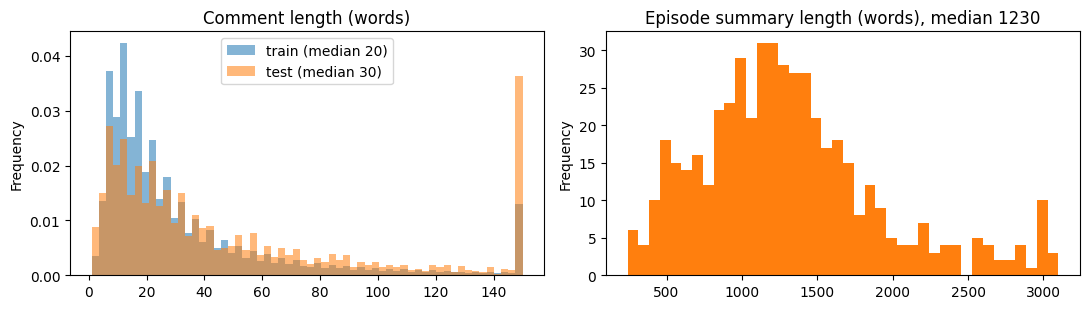

In [ ]:
# @title 2.3 Lengths: comments are short, summaries are long (the core difficulty)
import matplotlib.pyplot as plt
words = lambda s: s.str.split().str.len()
sum_len = pd.Series([len(t.split()) for v in summ.values() for t in v[1]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for name, df in [("train", train), ("test", test)]:
    words(df.comment).clip(upper=150).plot.hist(bins=60, alpha=.55, ax=ax[0], label=f"{name} (median {words(df.comment).median():.0f})", density=True)
ax[0].set_title("Comment length (words)"); ax[0].legend()
sum_len.plot.hist(bins=40, ax=ax[1], color="tab:orange")
ax[1].set_title(f"Episode summary length (words), median {sum_len.median():.0f}")
plt.tight_layout(); plt.show()

In [ ]:
# @title 2.4 Real samples: training rows (labels come from the Reddit thread, not checked by hand)
for r in train.sample(6, random_state=5).itertuples():
    print(f"[{r.show} ep {r.episode}]  {r.comment[:200]}")

[breaking_bad ep 62]  HE WANTED THEM TO THINK HE WAS STILL COOKING
[game_of_thrones ep 71]  I believe j'aime said those hurtful things to brienne so he can give himself a reason to leave and feel "guilt". He says "I did x for cersei, so now I'm going back again for her" is his saying, I'm me
[better_call_saul ep 61]  Saul gets caught. Kim comes out of retirement to defend him. Huell eats Carol Burnett
[better_call_saul ep 62]  I love how much it bothered him for Marion to say “i trusted you”
[my_hero_academia ep 74]  I half expected mirio do die
[game_of_thrones ep 72]  Yara Greyjoy was removed from the chat


In [ ]:
# @title 2.5 A test comment and the start of its episode's summary
r = test.iloc[1714]
eps, texts = summ[r.show]
print(f"COMMENT [{r.show} ep {r.episode}]: {r.comment}\n")
print(f"SUMMARY of ep {r.episode} ({len(texts[eps.index(r.episode)].split())} words):")
print(texts[eps.index(r.episode)][:900], "...")

COMMENT [attack_on_titan ep 82]: Guys did Falco saying “he’s seen Connie before” mean he’s slowly inheriting Ymir’s memories??

SUMMARY of ep 82 (1781 words):
The Military Police are busy rescuing survivors in Trost District following the collapse of the Walls and the march of the Wall Titans. Hitch Dreyse tends to an injured woman who laments the destruction of her house which was destroyed due to the rumbling. Nearby, people argue over whether Eren Jaeger's actions are justified given that people have been killed by the falling Walls. Another MP notices the trouble brewing and Hitch agrees that the two sides are going to clash. Hitch goes to organize riot gear for the Military Police when she spots damp footsteps coming out from the basement. She follows them to a room where she is ambushed by Annie Leonhart who threatens to cut her throat. Hitch throws her though and comments on how weak Annie is compared to how she used to be. Only then does Annie realize she attacked her former ro

In [ ]:
# @title 2.6 Relevance labels for the filter: about plot (0) or not (1)?
rel = pd.concat([pd.read_csv(f"{PROJECT}/data/raw/filtering/handlabeled/{s}.csv", header=None) for s in ["train", "dev", "test"]])
rel.columns = ["irrelevant", "comment", "show", "episode"]
print(f"{len(rel):,} hand-labelled comments, {rel.irrelevant.mean():.0%} irrelevant")
display(rel.groupby("show").irrelevant.agg(n="size", share_irrelevant="mean").round(2))
for lab in (1, 0):
    print("\nIRRELEVANT examples:" if lab else "\nRELEVANT examples:")
    for c in rel[(rel.irrelevant == lab) & rel.show.isin(["attack_on_titan", "legend_of_korra"])].comment.sample(4, random_state=4):
        print("  -", str(c)[:160])

11,032 hand-labelled comments, 47% irrelevant


,n,share_irrelevant
show,,
arcane,364,0.32
attack_on_titan,2126,0.41
demon_slayer_kimetsu_no_yaiba,535,0.56
dr_stone,2702,0.46
kaguya_sama_love_is_war,613,0.60
legend_of_korra,2436,0.44
mob_psycho_100,704,0.59
spy_x_family,1552,0.48



IRRELEVANT examples:
  - That was.. certainly an episode of Attack on titan
  - Man, these past few episodes have been real luckluster.
  - OH GOD LIN!!!
  - I noticed some resemblance in reiner and erwin, both are super tired of what they've been thru and want to die. It's just that people are not letting reiner die

RELEVANT examples:
  - Loved the slow motion backflip Mako did during the fight
  - The writing in this show seems to be a bit too juvenile for my tastes. When things get serious, they seem wooden and grandiose. Like Korra, I must get over what
  - Why did they Detain Falco and 300 soldiers that drank Zekes Spinal fluid? Was it because they wanted to keep them away from zeke so zeke doesn’t turn them into 
  - Sure, Yelena made up some details regarding her history after drinking the Monkey King Kool-Aid and sure, Yelena took being called out like that to air out some


In [ ]:
# @title 2.7 How good is random guessing? (the floor for MRR)
rand = {s: np.mean([1 / k for k in range(1, len(summ[s][0]) + 1)]) for s in test.show.unique()}
print({s: round(v, 3) for s, v in rand.items()})
print("random MRR over the test set:", round(np.mean([rand[s] for s in test.show]), 3))

{'attack_on_titan': np.float64(0.076), 'kaguya_sama_love_is_war': np.float64(0.187), 'legend_of_korra': np.float64(0.144), 'arcane': np.float64(0.314)}
random MRR over the test set: 0.134


## 3. How we score: MRR

For each comment, every episode of its show gets a score. We sort episodes by score and find the **rank** of the correct episode. Reciprocal rank = 1/rank; **MRR** is the average over all comments. Rank 1 → 1.0, rank 2 → 0.5, rank 10 → 0.1. We also report top-1 and top-3 accuracy. Every model in this project goes through this same `evaluate` function, so all numbers are comparable.

In [ ]:
show("common.py", 49, 67)

**`src/common.py`** lines 49–67

def evaluate(df, scores, name=None):
    """scores: list (one per comment) of arrays aligned to that show's episode list.
    Returns dict with MRR, top-1, top-3 accuracy, overall and per show."""
    summ = load_summaries()
    rr, top1, top3, shows = [], [], [], []
    for (show, ep), s in zip(df[["show", "episode"]].itertuples(index=False), scores):
        eps = summ[show][0]
        gold = eps.index(ep)
        rank = 1 + int((np.asarray(s) > s[gold]).sum())
        rr.append(1 / rank)
        top1.append(rank == 1)
        top3.append(rank <= 3)
        shows.append(show)
    res = pd.DataFrame({"show": shows, "rr": rr, "top1": top1, "top3": top3})
    out = {"model": name, "MRR": res.rr.mean(), "top1": res.top1.mean(), "top3": res.top3.mean()}
    for show, g in res.groupby("show"):
        out[f"MRR_{show}"] = g.rr.mean()
    return out

## 4. v0: BM25 (word matching), the sanity check

BM25 scores a summary by the comment words it contains. Rare words count more, repeats count less, long summaries are penalised. **Why first:** if our loading or MRR code had a bug, we would not match the paper's BM25 (0.368). We do (0.363), so the pipeline is correct.

In [ ]:
show("bm25.py")
!python bm25.py val
!python bm25.py test

**`src/bm25.py`**

"""Lexical baseline: BM25 over each show's episode summaries (whole summary and chunked)."""
import sys

import numpy as np
from rank_bm25 import BM25Okapi

from common import append_result, chunk_text, evaluate, load_split, load_summaries, save_scores, tokenize

split = sys.argv[1] if len(sys.argv) > 1 else "test"
summ = load_summaries()
df = load_split(split)

for variant in ["bm25", "bm25_chunks"]:
    index = {}
    for show, (eps, texts) in summ.items():
        if variant == "bm25":
            docs, owner = texts, list(range(len(texts)))
        else:
            docs, owner = [], []
            for i, t in enumerate(texts):
                for c in chunk_text(t):
                    docs.append(c)
                    owner.append(i)
        index[show] = (BM25Okapi([tokenize(d) for d in docs]), np.array(owner), len(texts))
    scores = []
    for show, comment in df[["show", "comment"]].itertuples(index=False):
        bm, owner, n = index[show]
        s = bm.get_scores(tokenize(comment))
        ep_scores = np.full(n, -1e9)
        np.maximum.at(ep_scores, owner, s)  # MaxP: best chunk per episode
        scores.append(ep_scores)
    save_scores(variant, split, scores)
    row = evaluate(df, scores, variant) | {"split": split}
    append_result(row)
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

{'model': 'bm25', 'MRR': np.float64(0.4087), 'top1': np.float64(0.2623), 'top3': np.float64(0.4568), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.3221), 'MRR_dr_stone': np.float64(0.3841), 'MRR_mob_psycho_100': np.float64(0.3539), 'MRR_spy_x_family': np.float64(0.4971), 'split': 'val'}


{'model': 'bm25_chunks', 'MRR': np.float64(0.4061), 'top1': np.float64(0.258), 'top3': np.float64(0.4528), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.2784), 'MRR_dr_stone': np.float64(0.3747), 'MRR_mob_psycho_100': np.float64(0.3594), 'MRR_spy_x_family': np.float64(0.5159), 'split': 'val'}


{'model': 'bm25', 'MRR': np.float64(0.3556), 'top1': np.float64(0.2113), 'top3': np.float64(0.3987), 'MRR_arcane': np.float64(0.4403), 'MRR_attack_on_titan': np.float64(0.2749), 'MRR_kaguya_sama_love_is_war': np.float64(0.3823), 'MRR_legend_of_korra': np.float64(0.4091), 'split': 'test'}


{'model': 'bm25_chunks', 'MRR': np.float64(0.3628), 'top1': np.float64(0.2119), 'top3': np.float64(0.4132), 'MRR_arcane': np.float64(0.453), 'MRR_attack_on_titan': np.float64(0.282), 'MRR_kaguya_sama_love_is_war': np.float64(0.4115), 'MRR_legend_of_korra': np.float64(0.4113), 'split': 'test'}


## 5. Chunking: why we cut summaries into pieces

A comment is about one scene; a summary covers a whole episode. One vector for 1,800 words averages that scene away. So we cut each summary into 200-word windows, moving 150 words at a time (50 words overlap), and give an episode the score of its **best** chunk ("MaxP").

In [ ]:
show("common.py", 37, 43)
t = summ["attack_on_titan"][1][0]
ch = chunk_text(t)
print(f"one summary: {len(t.split())} words -> {len(ch)} chunks")
all_chunks = [c for v in summ.values() for t in v[1] for c in chunk_text(t)]
print(f"all summaries: {len(all_chunks):,} chunks")

**`src/common.py`** lines 37–43

def chunk_text(text, size=200, stride=150):
    """Split a long summary into overlapping word windows (for short-context models)."""
    words = text.split()
    if len(words) <= size:
        return [text]
    return [" ".join(words[i:i + size]) for i in range(0, max(1, len(words) - size + stride), stride)]

one summary: 1264 words -> 9 chunks
all summaries: 4,424 chunks


In [ ]:
# @title 5.1 How many tokens is a 200-word chunk? (the model has a token limit)
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("nomic-ai/modernbert-embed-base")
L = np.array([len(tok("search_document: " + c)["input_ids"]) for c in all_chunks])
print(f"tokens per chunk: median {np.median(L):.0f}, 90th pct {np.percentile(L, 90):.0f}")
print(f"share of chunks longer than 256 tokens (the training limit): {(L > 256).mean():.0%}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


tokens per chunk: median 262, 90th pct 284
share of chunks longer than 256 tokens (the training limit): 65%


## 6. v1: ready-made embedding models (no training)

A bi-encoder turns each text into a vector of 768 numbers; similar meaning → similar direction. The comment and each chunk are encoded **separately**, so chunk vectors are computed once and reused for every comment (fast). We tried 5 models to pick the best starting point: small vs big, old vs new, short vs long context. `full` = whole summary in one vector, `chunks` = MaxP over chunks.

In [ ]:
show("zeroshot.py")
if RUN_ZEROSHOT:
    !python zeroshot.py test
    !python zeroshot.py val nomic_modernbert
results("test")

**`src/zeroshot.py`**

"""Off-the-shelf embedding models (no training): embed comments and summaries, rank by cosine.

Two ways to handle long summaries:
  full   - feed the whole summary (only for long-context models)
  chunks - split into ~200-word windows and take the best window per episode (MaxP)
"""
import sys
import time

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

from common import append_result, chunk_text, evaluate, load_split, load_summaries, save_scores

# name -> (hf id, max tokens, query prefix, doc prefix)
MODELS = {
    "minilm": ("sentence-transformers/all-MiniLM-L6-v2", 256, "", ""),
    "bge_base": ("BAAI/bge-base-en-v1.5", 512, "Represent this sentence for searching relevant passages: ", ""),
    "gte_modernbert": ("Alibaba-NLP/gte-modernbert-base", 8192, "", ""),
    "nomic_modernbert": ("nomic-ai/modernbert-embed-base", 8192, "search_query: ", "search_document: "),
    "bge_m3": ("BAAI/bge-m3", 8192, "", ""),
}

split = sys.argv[1] if len(sys.argv) > 1 else "test"
names = sys.argv[2].split(",") if len(sys.argv) > 2 else list(MODELS)
summ = load_summaries()
df = load_split(split)
shows_needed = sorted(df.show.unique())

for name in names:
    hf, max_len, qp, dp = MODELS[name]
    t0 = time.time()
    model = SentenceTransformer(hf, device="cuda", model_kwargs={"torch_dtype": torch.float16}, trust_remote_code=True)
    model.max_seq_length = max_len
    q = model.encode([qp + c for c in df.comment], batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
    modes = ["chunks"] + (["full"] if max_len >= 4096 else [])
    for mode in modes:
        ep_emb = {}
        for show in shows_needed:
            eps, texts = summ[show]
            if mode == "full":
                docs, owner = texts, list(range(len(texts)))
            else:
                docs, owner = [], []
                for i, t in enumerate(texts):
                    for c in chunk_text(t):
                        docs.append(c)
                        owner.append(i)
            e = model.encode([dp + d for d in docs], batch_size=4 if mode == "full" else 32,
                             normalize_embeddings=True, convert_to_numpy=True)
            ep_emb[show] = (e, np.array(owner), len(texts))
        scores = []
        for i, show in enumerate(df.show):
            e, owner, n = ep_emb[show]
            s = e @ q[i]
            ep_scores = np.full(n, -1e9)
            np.maximum.at(ep_scores, owner, s)
            scores.append(ep_scores)
        tag = f"{name}_{mode}"
        save_scores(tag, split, scores)
        row = evaluate(df, scores, tag) | {"split": split, "secs": round(time.time() - t0, 1)}
        append_result(row)
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}, flush=True)
    del model
    torch.cuda.empty_cache()

Loading weights: 100% 103/103 [00:00<00:00, 3554.17it/s]


{'model': 'minilm_chunks', 'MRR': np.float64(0.4234), 'top1': np.float64(0.2657), 'top3': np.float64(0.4873), 'MRR_arcane': np.float64(0.5409), 'MRR_attack_on_titan': np.float64(0.3418), 'MRR_kaguya_sama_love_is_war': np.float64(0.434), 'MRR_legend_of_korra': np.float64(0.4745), 'split': 'test', 'secs': 9.5}


Loading weights: 100% 199/199 [00:00<00:00, 2994.01it/s]


{'model': 'bge_base_chunks', 'MRR': np.float64(0.3691), 'top1': np.float64(0.2155), 'top3': np.float64(0.4248), 'MRR_arcane': np.float64(0.543), 'MRR_attack_on_titan': np.float64(0.271), 'MRR_kaguya_sama_love_is_war': np.float64(0.41), 'MRR_legend_of_korra': np.float64(0.4196), 'split': 'test', 'secs': 13.6}


... (9 outputs left out)

Loading weights: 100% 134/134 [00:00<00:00, 2537.06it/s]


{'model': 'nomic_modernbert_chunks', 'MRR': np.float64(0.4975), 'top1': np.float64(0.3369), 'top3': np.float64(0.5777), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.38), 'MRR_dr_stone': np.float64(0.4877), 'MRR_mob_psycho_100': np.float64(0.439), 'MRR_spy_x_family': np.float64(0.57), 'split': 'val', 'secs': 15.8}


{'model': 'nomic_modernbert_full', 'MRR': np.float64(0.4509), 'top1': np.float64(0.2917), 'top3': np.float64(0.5156), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.3915), 'MRR_dr_stone': np.float64(0.427), 'MRR_mob_psycho_100': np.float64(0.4276), 'MRR_spy_x_family': np.float64(0.519), 'split': 'val', 'secs': 19.6}


,model,MRR,top1,top3
0,bm25,0.356,0.211,0.399
1,bm25_chunks,0.363,0.212,0.413
2,bge_base_chunks,0.369,0.215,0.425
3,bge_m3_full,0.415,0.259,0.475
4,gte_modernbert_full,0.416,0.262,0.475
5,minilm_chunks,0.423,0.266,0.487
6,nomic_modernbert_full,0.425,0.271,0.486
7,gte_modernbert_chunks,0.448,0.289,0.529
8,bge_m3_chunks,0.458,0.298,0.531
9,nomic_modernbert_chunks,0.476,0.318,0.551


## 7. Inside the model: nomic ModernBERT embed

**ModernBERT** (Warner et al., Dec 2024) is a rebuilt BERT: 8,192-token context, local+global attention, newer building blocks, trained on 2 trillion tokens. **Nomic** trained it further on query–document pairs so its averaged output is a good search vector. Below: the pipeline, the layers, the sizes, and what the tokenizer and the vectors actually look like.

In [ ]:
# @title 7.1 The three stages of the sentence-transformer pipeline
from sentence_transformers import SentenceTransformer
base = SentenceTransformer("nomic-ai/modernbert-embed-base", device="cuda")
print(base)

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'ModernBertModel'})
  (1): Pooling({'embedding_dimension': 768, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({})
)


In [ ]:
# @title 7.2 The transformer's settings (these are fixed by the pretrained model)
cfg = base[0].auto_model.config
for k in ["hidden_size", "num_hidden_layers", "num_attention_heads", "intermediate_size", "vocab_size",
          "max_position_embeddings", "global_attn_every_n_layers", "local_attention", "hidden_activation"]:
    print(f"{k:28s} {getattr(cfg, k, None)}")

hidden_size                  768
num_hidden_layers            22
num_attention_heads          12
intermediate_size            1152
vocab_size                   50368
max_position_embeddings      8192
global_attn_every_n_layers   3
local_attention              128
hidden_activation            gelu


In [ ]:
# @title 7.3 All the layers, and where the 149M parameters are
m = base[0].auto_model
print(m)
groups = {}
for n, p in m.named_parameters():
    key = "embeddings" if n.startswith("embeddings") else ("layers" if n.startswith("layers") else n.split(".")[0])
    groups[key] = groups.get(key, 0) + p.numel()
print({k: f"{v/1e6:.1f}M" for k, v in groups.items()}, "| total", f"{sum(groups.values())/1e6:.1f}M")

ModernBertModel(
  (embeddings): ModernBertEmbeddings(
    (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
    (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
    (drop): Dropout(p=0.0, inplace=False)
  )
  (layers): ModuleList(
    (0): ModernBertEncoderLayer(
      (attn_norm): Identity()
      (attn): ModernBertAttention(
        (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
        (Wo): Linear(in_features=768, out_features=768, bias=False)
        (out_drop): Identity()
      )
      (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
      (mlp): ModernBertMLP(
        (Wi): Linear(in_features=768, out_features=2304, bias=False)
        (act): GELUActivation()
        (drop): Dropout(p=0.0, inplace=False)
        (Wo): Linear(in_features=1152, out_features=768, bias=False)
      )
    )
    (1-21): 21 x ModernBertEncoderLayer(
      (attn_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bi

In [ ]:
# @title 7.4 Tokens: how the model sees a comment
c = test.comment[1752]
ids = tok("search_query: " + c)["input_ids"]
print(c); print(tok.convert_ids_to_tokens(ids))

Tenzin is dead. Just going to call it now. I hope I'm wrong.
['[CLS]', 'search', '_', 'query', ':', 'ĠT', 'enz', 'in', 'Ġis', 'Ġdead', '.', 'ĠJust', 'Ġgoing', 'Ġto', 'Ġcall', 'Ġit', 'Ġnow', '.', 'ĠI', 'Ġhope', 'ĠI', "'m", 'Ġwrong', '.', '[SEP]']


In [ ]:
# @title 7.5 Vectors and cosine similarity in practice
texts_ = ["search_query: Tenzin is dead. Just going to call it now.",
          "search_document: Tenzin battles Zaheer ... is quickly worn down, becoming severely injured.",
          "search_document: Korra and Mako go on a date to a fancy restaurant."]
E = base.encode(texts_, normalize_embeddings=True)
print("vector shape:", E.shape, "| first 6 numbers:", E[0][:6].round(3))
print("cosine(comment, fight scene) =", round(float(E[0] @ E[1]), 3))
print("cosine(comment, date scene)  =", round(float(E[0] @ E[2]), 3))
del base; torch.cuda.empty_cache()

vector shape: (3, 768) | first 6 numbers: [-0.085  0.03   0.014 -0.048 -0.04  -0.032]
cosine(comment, fight scene) = 0.438
cosine(comment, date scene)  = 0.031


## 8. v2: fine-tuning on our task

**Idea (contrastive learning):** show the model triples and move vectors.
- *anchor* = a comment; *positive* = the best-matching chunk of the correct episode → pull closer
- *hard negative* = the best-matching chunk of a **wrong episode of the same show** → push away
- every other comment's chunks in the batch are free extra negatives (*in-batch negatives*)

The loss (Multiple Negatives Ranking Loss) is a softmax over similarities: each comment must pick its own positive out of all 128 chunks in the batch.

**Hyperparameters and why**

| Setting | Value | Why |
|---|---|---|
| training comments | 24,000 | ~15 min on L4; first run. More is the first thing to try. |
| cap per show | 15,000 | Game of Thrones would otherwise dominate |
| epochs | 1 | lots of data; each comment seen once |
| learning rate | 2e-5, 10% warm-up | standard for BERT fine-tuning; small so pretrained knowledge isn't destroyed |
| batch size | 64 (mini-batch 16, "Cached" loss) | more in-batch negatives; Cached = GradCache, behaves like 64 with the memory of 16 |
| fp16 | on | half the memory, faster |
| NO_DUPLICATES sampler | on | the same chunk twice in a batch would count as a false negative |
| max_seq_length | 256 | memory on the 6 GB laptop. 65% of chunks are longer (see 5.1). Easy thing to raise on L4. |
| positives chosen by | the untrained model | we don't know which part of the summary the comment is about |

In [ ]:
show("train_biencoder.py")
if RUN_TRAIN:
    !python train_biencoder.py 24000

**`src/train_biencoder.py`**

"""Fine-tune a bi-encoder (comment encoder = summary-chunk encoder) for spoiler matching.

Training pairs are built automatically:
  positive      = the chunk of the correct episode's summary most similar to the comment
                  (chosen with the zero-shot model, since we do not know which part the comment is about)
  hard negative = the most similar chunk from a *different* episode of the same show
Loss: MultipleNegativesRankingLoss (other pairs in the batch are extra negatives).
At test time: MaxP over chunks, exactly as in zeroshot.py.
"""
import json
import sys
import time

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import CachedMultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

from common import ROOT, append_result, chunk_text, evaluate, load_split, load_summaries, save_scores

BASE = "nomic-ai/modernbert-embed-base"
QP, DP = "search_query: ", "search_document: "
N_TRAIN = int(sys.argv[1]) if len(sys.argv) > 1 else 60000
CAP_PER_SHOW = 15000  # Game of Thrones has 127k comments; cap so one show does not dominate
TAG = sys.argv[2] if len(sys.argv) > 2 else f"ft_nomic_{N_TRAIN // 1000}k"
OUT = ROOT / "models" / TAG
rng = np.random.default_rng(0)

summ = load_summaries()


def show_chunks(model, shows):
    out = {}
    for show in shows:
        docs, owner = [], []
        for i, t in enumerate(summ[show][1]):
            for c in chunk_text(t):
                docs.append(c)
                owner.append(i)
        e = model.encode([DP + d for d in docs], batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
        out[show] = (docs, e, np.array(owner), len(summ[show][1]))
    return out


def score(model, df, chunks=None):
    chunks = chunks or show_chunks(model, sorted(df.show.unique()))
    q = model.encode([QP + c for c in df.comment], batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
    scores = []
    for i, show in enumerate(df.show):
        _, e, owner, n = chunks[show]
        s = np.full(n, -1e9)
        np.maximum.at(s, owner, e @ q[i])
        scores.append(s)
    return scores


# ---- 1. sample training comments (balanced-ish across shows)
train = load_split("train")
train = pd.concat([g.sample(min(len(g), CAP_PER_SHOW), random_state=0) for _, g in train.groupby("show")])
train = train.sample(min(N_TRAIN, len(train)), random_state=0).reset_index(drop=True)
print("train comments:", len(train), train.show.value_counts().to_dict(), flush=True)

# ---- 2. mine positive / hard-negative chunks with the zero-shot model
t0 = time.time()
model = SentenceTransformer(BASE, device="cuda")
model.max_seq_length = 256
ch = show_chunks(model, sorted(train.show.unique()))
q = model.encode([QP + c for c in train.comment], batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
anchors, pos, neg = [], [], []
summ_eps = {s: summ[s][0] for s in summ}
for i, (show, ep, comment) in enumerate(train.itertuples(index=False)):
    docs, e, owner, n = ch[show]
    gold = summ_eps[show].index(ep)
    sims = e @ q[i]
    gmask = owner == gold
    p = np.where(gmask)[0][np.argmax(sims[gmask])]
    nidx = np.where(~gmask)[0]
    hn = nidx[np.argmax(sims[nidx])]
    anchors.append(QP + comment)
    pos.append(DP + docs[p])
    neg.append(DP + docs[hn])
print(f"mined pairs in {time.time() - t0:.0f}s", flush=True)
ds = Dataset.from_dict({"anchor": anchors, "positive": pos, "negative": neg})

# ---- 3. train
args = SentenceTransformerTrainingArguments(
    output_dir=str(OUT / "ckpt"), num_train_epochs=1, per_device_train_batch_size=64,
    learning_rate=2e-5, warmup_ratio=0.1, fp16=True, batch_sampler=BatchSamplers.NO_DUPLICATES,
    logging_steps=100, save_strategy="no", report_to="none", seed=0,
)
loss = CachedMultipleNegativesRankingLoss(model, mini_batch_size=16

/content/Spoiler Matching/src/train_biencoder.py:19: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import CachedMultipleNegativesRankingLoss
/content/Spoiler Matching/src/train_biencoder.py:20: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


train comments: 24000 {'game_of_thrones': 5060, 'better_call_saul': 4972, 'breaking_bad': 4516, 'my_hero_academia': 4009, 'stranger_things': 2674, 'demon_slayer_kimetsu_no_yaiba': 1479, 'spy_x_family': 593, 'mob_psycho_100': 428, 'dr_stone': 269}


Loading weights: 100% 134/134 [00:00<00:00, 6117.41it/s]


mined pairs in 114s


... (376 outputs left out)

{'train_runtime': '894.7', 'train_samples_per_second': '26.82', 'train_steps_per_second': '0.419', 'train_loss': '1.932', 'epoch': '1'}
100% 375/375 [14:54<00:00,  2.39s/it]
trained in 895s
Writing model shards:   0% 0/1 [00:00<?, ?it/s]

Writing model shards: 100% 1/1 [00:00<00:00,  1.35it/s]


{'model': 'ft_nomic_24k', 'MRR': np.float64(0.5616), 'top1': np.float64(0.4051), 'top3': np.float64(0.6512), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.4799), 'MRR_dr_stone': np.float64(0.5499), 'MRR_mob_psycho_100': np.float64(0.4829), 'MRR_spy_x_family': np.float64(0.6339), 'split': 'val', 'secs': 8.5}


{'model': 'ft_nomic_24k', 'MRR': np.float64(0.5452), 'top1': np.float64(0.3939), 'top3': np.float64(0.63), 'MRR_arcane': np.float64(0.6233), 'MRR_attack_on_titan': np.float64(0.5029), 'MRR_kaguya_sama_love_is_war': np.float64(0.5349), 'MRR_legend_of_korra': np.float64(0.5715), 'split': 'test', 'secs': 12.8}


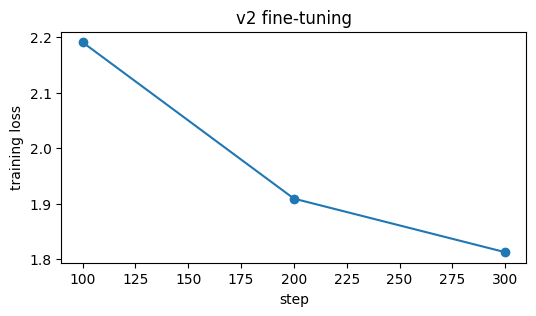

,model,MRR,top1,top3
0,bm25,0.356,0.211,0.399
1,bm25_chunks,0.363,0.212,0.413
2,bge_base_chunks,0.369,0.215,0.425
3,bge_m3_full,0.415,0.259,0.475
4,gte_modernbert_full,0.416,0.262,0.475
5,minilm_chunks,0.423,0.266,0.487
6,nomic_modernbert_full,0.425,0.271,0.486
7,gte_modernbert_chunks,0.448,0.289,0.529
8,bge_m3_chunks,0.458,0.298,0.531
9,nomic_modernbert_chunks,0.476,0.318,0.551


In [ ]:
# @title 8.1 Training loss curve
p = f"{PROJECT}/models/ft_nomic_24k/train_log.json"
if os.path.exists(p):
    log = [x for x in json.load(open(p)) if "loss" in x]
    plt.figure(figsize=(6, 3)); plt.plot([x["step"] for x in log], [x["loss"] for x in log], marker="o")
    plt.xlabel("step"); plt.ylabel("training loss"); plt.title("v2 fine-tuning"); plt.show()
else:
    print("no train_log.json yet (the 19 Nov laptop run didn't save it); set RUN_TRAIN = True")
results("test")

## 9. v3: mixing in BM25

BM25 and the embedding model make **different mistakes**: BM25 nails rare exact words, embeddings handle meaning and spelling variants. Per comment, each model's scores are z-scored (so the scales match) and added: `final = z(dense) + w · z(bm25)`. `w` is picked on **val**, never on test.

**`src/fuse.py`**

"""Mix two rankers' scores (e.g. fine-tuned bi-encoder + BM25) into one score per episode.

Why: they make different mistakes. BM25 wins on rare exact words ("pink eyes", "Powder");
the embedding model wins on meaning and spelling variants ("Connie"/"Conny", "dead"/"injured").

How: the two score types live on different scales (cosine ~0-1, BM25 ~0-40), so for EACH comment
we z-score each model's episode scores (subtract the mean, divide by the std), then add:
    final = z(dense) + w * z(bm25)
The weight w is chosen on VAL only; test is touched once with that w.
(This is exactly how the 0.557 result from 19 Nov was made: w = 0.3, bm25 = bm25_chunks.)

Usage: python fuse.py <dense tag> [bm25 tag]      e.g. python fuse.py ft_nomic_24k bm25_chunks
"""
import sys

import numpy as np

from common import append_result, evaluate, load_scores, load_split, save_scores

WEIGHTS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]


def z(x):
    x = np.asarray(x, float)
    return (x - x.mean()) / (x.std() + 1e-9)


def mix(a, b, w):
    return [z(x) + w * z(y) for x, y in zip(a, b)]


def sweep(dense, sparse, split="val"):
    """MRR on `split` for every weight in WEIGHTS."""
    df = load_split(split)
    d, s = load_scores(dense, split), load_scores(sparse, split)
    return {w: evaluate(df, mix(d, s, w))["MRR"] for w in WEIGHTS}


if __name__ == "__main__":
    dense = sys.argv[1] if len(sys.argv) > 1 else "ft_nomic_24k"
    sparse = sys.argv[2] if len(sys.argv) > 2 else "bm25_chunks"
    val_mrr = sweep(dense, sparse, "val")
    for w, mrr in val_mrr.items():
        print(f"w={w:<4} val MRR {mrr:.4f}")
    best = max(val_mrr, key=val_mrr.get)
    print(f"best w on val: {best}")

    tag = f"{dense}+bm25_w{best}"
    for split in ["val", "test"]:
        df = load_split(split)
        s = mix(load_scores(dense, split), load_scores(sparse, split), best)
        save_scores(tag, split, s)
        row = evaluate(df, s, tag) | {"split": split}
        append_result(row)
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

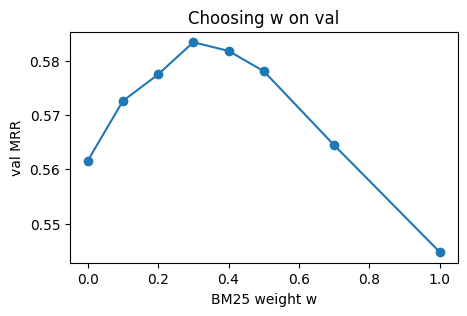

w=0.0  val MRR 0.5616
w=0.1  val MRR 0.5726
w=0.2  val MRR 0.5775
w=0.3  val MRR 0.5834
w=0.4  val MRR 0.5818
w=0.5  val MRR 0.5781
w=0.7  val MRR 0.5644
w=1.0  val MRR 0.5447
best w on val: 0.3
{'model': 'ft_nomic_24k+bm25_w0.3', 'MRR': np.float64(0.5834), 'top1': np.float64(0.4395), 'top3': np.float64(0.6602), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.495), 'MRR_dr_stone': np.float64(0.5633), 'MRR_mob_psycho_100': np.float64(0.5091), 'MRR_spy_x_family': np.float64(0.6714), 'split': 'val'}


{'model': 'ft_nomic_24k+bm25_w0.3', 'MRR': np.float64(0.5585), 'top1': np.float64(0.409), 'top3': np.float64(0.6419), 'MRR_arcane': np.float64(0.6255), 'MRR_attack_on_titan': np.float64(0.5125), 'MRR_kaguya_sama_love_is_war': np.float64(0.5614), 'MRR_legend_of_korra': np.float64(0.5879), 'split': 'test'}


In [ ]:
show("fuse.py")
from fuse import sweep
sw = sweep("ft_nomic_24k", "bm25_chunks", "val")
plt.figure(figsize=(5, 3)); plt.plot(list(sw), list(sw.values()), marker="o")
plt.xlabel("BM25 weight w"); plt.ylabel("val MRR"); plt.title("Choosing w on val"); plt.show()
!python fuse.py ft_nomic_24k bm25_chunks

## 10. Reranker test (two-stage)

The fast model picks the top 10 episodes; a cross-encoder (reads comment + chunk **together**, slower but more precise) re-scores only those. With an off-the-shelf reranker this gave 0.560 vs 0.557 and took 41 min on the laptop, so it was dropped. A reranker **fine-tuned on our data** is one of the next experiments.

In [ ]:
show("rerank.py")
if RUN_RERANK:
    !python rerank.py ft_nomic_24k gte_rr chunks 10 test

**`src/rerank.py`**

"""Two-stage matching: a fast bi-encoder picks the top-K episodes, a cross-encoder re-scores them.

Cross-encoder reads (comment, summary text) together. Long summaries are handled two ways:
  full   - whole summary in one pass (ModernBERT-based reranker, 8k context)
  chunks - best ~200-word chunk per episode (MaxP)

Usage: python rerank.py <first-stage tag> <reranker name> <mode full|chunks> [K] [split]
"""
import sys
import time

import numpy as np
import torch
from sentence_transformers import CrossEncoder

from common import append_result, chunk_text, evaluate, load_scores, load_split, load_summaries, save_scores

RERANKERS = {
    "gte_rr": ("Alibaba-NLP/gte-reranker-modernbert-base", 8192),
    "bge_rr_m3": ("BAAI/bge-reranker-v2-m3", 8192),
}
first, rr_name, mode = sys.argv[1], sys.argv[2], sys.argv[3]
K = int(sys.argv[4]) if len(sys.argv) > 4 else 10
split = sys.argv[5] if len(sys.argv) > 5 else "test"
hf_or_path, max_len = RERANKERS.get(rr_name, (rr_name, 8192))

summ = load_summaries()
df = load_split(split)
base = load_scores(first, split)
model = CrossEncoder(hf_or_path, device="cuda", max_length=max_len if mode == "full" else 384,
                     model_kwargs={"torch_dtype": torch.float16}, trust_remote_code=True)

t0 = time.time()
pairs, owner = [], []  # owner = (comment index, episode index)
for i, (show, comment) in enumerate(df[["show", "comment"]].itertuples(index=False)):
    top = np.argsort(-np.asarray(base[i], float))[:K]
    for j in top:
        text = summ[show][1][j]
        docs = [text] if mode == "full" else chunk_text(text)
        for d in docs:
            pairs.append((comment, d))
            owner.append((i, j))
print(f"{len(pairs):,} pairs", flush=True)
# sort by length so batches have similar lengths (much faster)
order = np.argsort([len(p[1]) for p in pairs])
pred = np.empty(len(pairs), dtype=float)
bs = 4 if mode == "full" else 64
pred[order] = model.predict([pairs[k] for k in order], batch_size=bs, show_progress_bar=False)

scores = [np.asarray(s, float) - 1e6 for s in base]  # non-reranked episodes stay below
best = {}
for (i, j), p in zip(owner, pred):
    best[(i, j)] = max(best.get((i, j), -1e9), p)
for (i, j), p in best.items():
    scores[i][j] = 1e6 + p
tag = f"{first}+{rr_name.split('/')[-1]}_{mode}_k{K}"
save_scores(tag, split, scores)
row = evaluate(df, scores, tag) | {"split": split, "secs": round(time.time() - t0, 1)}
append_result(row)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}, flush=True)

## 11. The progress-aware filter (the new part)

`P(spoiler for a viewer at episode k) = P(comment is about plot) × P(comment's episode > k)`
- **P(about plot)**: frozen nomic vectors + logistic regression, trained on the hand labels of the 4 non-test shows.
- **P(episode)**: softmax of the matching scores with a temperature fitted on val (calibration).
- **Test**: every test comment × every viewer position = 206,968 pairs. We compare spoilers caught at the same false-alarm rate.

In [ ]:
show("filter_eval.py")
!python filter_eval.py "ft_nomic_24k+bm25_w0.3"

**`src/filter_eval.py`**

"""End-to-end progress-aware spoiler filter (the part Tran et al. left as future work).

A viewer has watched episodes 1..k of a show. For every comment we decide: hide or show.
Ground truth: a comment is a spoiler for this viewer if it is RELEVANT (talks about plot events)
and comes from an episode thread e > k. Irrelevant comments ("this episode was fun") are never spoilers.

Systems compared (all use the same test comments, 4 unseen shows):
  hide_nothing        - no filter
  classic_detector    - hide every comment the relevance classifier flags as plot-revealing
                        (what a normal yes/no spoiler detector does; ignores viewer progress)
  progress_aware      - P(spoiler | k) = P(relevant) * P(episode > k); hide if above threshold
  progress_aware_oracle_rel - same but with the true relevance label (isolates matching quality)

Relevance classifier: frozen embedding model + logistic regression, trained on the hand-labelled
relevant/irrelevant comments of the NON-test shows only.

Usage: python filter_eval.py <matching model tag>   (needs results/scores/<tag>__val.npy and __test.npy)
"""
import sys

import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize_scalar
from scipy.special import softmax
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from common import RESULTS, ROOT, load_scores, load_split, load_summaries

TAG = sys.argv[1]
summ = load_summaries()
TEST_SHOWS = {"attack_on_titan", "kaguya_sama_love_is_war", "legend_of_korra", "arcane"}

# ---- relevance classifier
f = pd.concat([pd.read_csv(ROOT / f"data/raw/filtering/handlabeled/{s}.csv", header=None) for s in ["train", "dev", "test"]])
f.columns = ["irrelevant", "comment", "show", "episode"]
f["comment"] = f.comment.astype(str)
tr = f[~f.show.isin(TEST_SHOWS)]
te = f[f.show.isin(TEST_SHOWS)].reset_index(drop=True)
emb = SentenceTransformer("nomic-ai/modernbert-embed-base", device="cuda", model_kwargs={"torch_dtype": torch.float16})
emb.max_seq_length = 256
enc = lambda xs: emb.encode(["classification: " + x for x in xs], batch_size=128, normalize_embeddings=True)
clf = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(enc(tr.comment.tolist()), 1 - tr.irrelevant)
te["p_rel"] = clf.predict_proba(enc(te.comment.tolist()))[:, 1]
rel_auc = roc_auc_score(1 - te.irrelevant, te.p_rel)
rel_acc = ((te.p_rel > 0.5) == (te.irrelevant == 0)).mean()
print(f"relevance classifier on test shows: AUC {rel_auc:.3f}, acc {rel_acc:.3f}")

# ---- episode probabilities from matching scores; temperature fitted on val
val, test = load_split("val"), load_split("test")
sv, st = load_scores(TAG, "val"), load_scores(TAG, "test")


def nll(logt, df, scores):
    t = np.exp(logt)
    return -np.mean([np.log(softmax(np.asarray(s, float) / t)[summ[sh][0].index(ep)] + 1e-12)
                     for (sh, ep), s in zip(df[["show", "episode"]].itertuples(index=False), scores)])


logt = minimize_scalar(nll, bounds=(-8, 3), args=(val, sv), method="bounded").x
T = np.exp(logt)
print(f"temperature {T:.4f}")
pep = {c: softmax(np.asarray(s, float) / T) for c, s in zip(test.comment, st)}

# irrelevant comments have no matching scores in the dataset: score them with the same matching model
# outputs are only needed through P(relevant) for them; P(ep > k) for irrelevant comments uses a uniform guess
# (a conservative choice: it only matters when the relevance classifier is wrong).

# ---- simulate viewers at every progress point k
rows = []
for r in te.itertuples(index=False):
    eps = summ[r.show][0]
    n = len(eps)
    if r.irrelevant == 0:
        p = pep[r.comment]
    else:
        p = np.full(n, 1 / n)
    tail = np.cumsum(p[::-1])[::-1]  # tail[j] = P(episode index >= j)
    pos = eps.index(r.episode) if r.episode in eps else int(np.searchsorted(eps, r.episode))
    for j in range(n - 1):  # viewer has watched eps[0..j]
        spo

Loading weights: 100% 134/134 [00:00<00:00, 2153.96it/s]


relevance classifier on test shows: AUC 0.855, acc 0.776


temperature 0.7480


viewer-comment pairs: 206,968  spoiler share: 0.441
                   system         matching_model  spoilers_hidden  safe_hidden  safe_plot_comments_hidden   AUC  spoilers_hidden_at_classic_fpr  spoilers_hidden_at_5pct_safe_hidden  spoilers_hidden_at_10pct_safe_hidden
             hide_nothing ft_nomic_24k+bm25_w0.3            0.000        0.000                      0.000 0.500                           0.000                                0.000                                 0.000
         classic_detector ft_nomic_24k+bm25_w0.3            0.830        0.357                      0.735 0.804                           0.830                                0.227                                 0.372
           progress_aware ft_nomic_24k+bm25_w0.3            0.568        0.057                      0.037 0.890                           0.918                                0.540                                 0.680
progress_aware_oracle_rel ft_nomic_24k+bm25_w0.3            0.797       

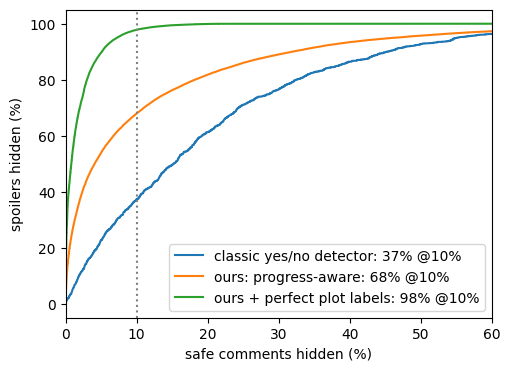

In [ ]:
# @title 11.1 The trade-off curve: spoilers caught vs safe comments hidden by mistake
from sklearn.metrics import roc_curve
sim = pd.read_parquet(f"{PROJECT}/results/filter_sim__ft_nomic_24k_bm25_w0.3.parquet")
plt.figure(figsize=(5.5, 4))
for col, label in [("classic_detector", "classic yes/no detector"), ("progress_aware", "ours: progress-aware"),
                   ("progress_aware_oracle_rel", "ours + perfect plot labels")]:
    fpr, tpr, _ = roc_curve(sim.spoiler, sim[col]); k = np.searchsorted(fpr, .10)
    plt.plot(fpr * 100, tpr * 100, label=f"{label}: {tpr[k]:.0%} @10%")
plt.axvline(10, ls=":", c="gray"); plt.xlim(0, 60)
plt.xlabel("safe comments hidden (%)"); plt.ylabel("spoilers hidden (%)"); plt.legend(); plt.show()

## 12. Speed (bi-encoder vs the paper's Longformer cross-encoder)

In [ ]:
show("speed.py")
if RUN_SPEED:
    !python speed.py
print(json.dumps(json.load(open(f"{PROJECT}/results/speed.json")), indent=1))
print("\nNote: the Longformer number is an estimate from timing single pairs; claim ~1,000-2,000x, not 4,600x.")

**`src/speed.py`**

"""Speed and size comparison on the same laptop GPU (RTX 4050 6 GB, fp16).

Ours (bi-encoder): summaries are encoded ONCE and cached; each new comment needs one short pass.
Paper's best (Longformer cross-encoder): every (comment, episode summary) pair needs its own
long pass (up to 4,096 tokens). We time a random sample of real pairs and extrapolate.
Weights do not matter for speed, so the public longformer-base-4096 checkpoint is used.
"""
import json
import time

import numpy as np
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from common import RESULTS, ROOT, chunk_text, load_split, load_summaries

summ = load_summaries()
test = load_split("test")
n_pairs = int(sum(len(summ[s][0]) for s in test.show))
out = {"test_comments": len(test), "test_pairs_comment_x_episode": n_pairs}


def params(m):
    return sum(p.numel() for p in m.parameters())


# ---- ours
m = SentenceTransformer(str(ROOT / "models/ft_nomic_24k"), device="cuda").half()
m.max_seq_length = 256
docs = [c for s in sorted(test.show.unique()) for t in summ[s][1] for c in chunk_text(t)]
m.encode(["warm up"] * 64)
torch.cuda.synchronize(); t0 = time.time()
m.encode(["search_document: " + d for d in docs], batch_size=64)
torch.cuda.synchronize(); t_docs = time.time() - t0
t0 = time.time()
m.encode(["search_query: " + c for c in test.comment], batch_size=128)
torch.cuda.synchronize(); t_q = time.time() - t0
lat = []
for c in test.comment.sample(200, random_state=0):
    t0 = time.time(); m.encode(["search_query: " + c]); torch.cuda.synchronize(); lat.append(time.time() - t0)
out["ours_params_M"] = params(m) / 1e6
out["ours_summary_index_secs_once"] = t_docs
out["ours_all_test_comments_secs"] = t_q
out["ours_comments_per_sec"] = len(test) / t_q
out["ours_single_comment_ms"] = 1000 * float(np.median(lat))
del m; torch.cuda.empty_cache()

# ---- Longformer cross-encoder (paper's best model type)
tok = AutoTokenizer.from_pretrained("allenai/longformer-base-4096")
lf = AutoModelForSequenceClassification.from_pretrained("allenai/longformer-base-4096", num_labels=1).cuda().half().eval()
rng = np.random.default_rng(0)
sample = []
for i in rng.choice(len(test), 48, replace=False):
    show, comment = test.show[i], test.comment[i]
    j = rng.integers(len(summ[show][1]))
    sample.append((comment, summ[show][1][j]))
lens = [len(tok(c, s, truncation=True, max_length=4096)["input_ids"]) for c, s in sample]
with torch.no_grad():
    b = tok([sample[0][0]] * 2, [sample[0][1]] * 2, truncation=True, max_length=4096, padding=True, return_tensors="pt").to("cuda")
    lf(**b)
    torch.cuda.synchronize(); t0 = time.time()
    for k in range(0, len(sample), 2):
        c, s = zip(*sample[k:k + 2])
        b = tok(list(c), list(s), truncation=True, max_length=4096, padding=True, return_tensors="pt").to("cuda")
        lf(**b)
    torch.cuda.synchronize(); t_lf = time.time() - t0
per_pair = t_lf / len(sample)
avg_eps = n_pairs / len(test)
out["longformer_params_M"] = params(lf) / 1e6
out["longformer_median_pair_tokens"] = float(np.median(lens))
out["longformer_secs_per_pair"] = per_pair
out["longformer_all_test_secs_est"] = per_pair * n_pairs
out["longformer_comments_per_sec_est"] = 1 / (per_pair * avg_eps)
out["longformer_single_comment_ms_est"] = 1000 * per_pair * avg_eps
out["speedup_all_test"] = out["longformer_all_test_secs_est"] / t_q
json.dump(out, open(RESULTS / "speed.json", "w"), indent=2)
print(json.dumps(out, indent=2))

{
 "test_comments": 3105,
 "test_pairs_comment_x_episode": 120963,
 "ours_params_M": 149.014272,
 "ours_summary_index_secs_once": 12.488728284835815,
 "ours_all_test_comments_secs": 11.860560894012451,
 "ours_comments_per_sec": 261.79200357779814,
 "ours_single_comment_ms": 19.894123077392578,
 "longformer_params_M": 148.660225,
 "longformer_median_pair_tokens": 2070.0,
 "longformer_secs_per_pair": 0.45080845057964325,
 "longformer_all_test_secs_est": 54531.14260746539,
 "longformer_comments_per_sec_est": 0.056939940216380526,
 "longformer_single_comment_ms_est": 17562.364768909945,
 "speedup_all_test": 4597.686660417068
}

Note: the Longformer number is an estimate from timing single pairs; claim ~1,000-2,000x, not 4,600x.


## 13. v4 (A): a better training recipe (21–22 Nov)

Changes to v2's training, each aimed at a weak point we found:

| Change | v2 | v4 | Why |
|---|---|---|---|
| A1 training comments | 24,000 | all 71,972 (after the 15k-per-show cap) | v2 used a third of the usable data |
| A2 token limit | 256 | 384 | 65% of 200-word chunks were cut off (section 5.1) |
| A3 hard negatives per comment | 1 | 3 (best chunk of the 3 most similar wrong episodes) | more and harder "wrong answers" is what made DPR-style training work |
| A3 batch | 64 | 128 | more in-batch negatives (each comment competes with 128 × 5 chunks) |
| A5 cleaning (tested) | no | drop comments the plot classifier (section 15) gives P(plot) < 0.5 | the paper estimates ~12% of auto-labels are off-topic |

**Experiment design.** Changing everything at once wouldn't tell us *which* change helped, so there are three runs:
- **v4a** = v2's 24k comments + the new recipe (A2, A3) → effect of the recipe (compare with v2)
- **v4b** = v4a + cleaning → effect of cleaning (A5), at the same 24k size
- **v4** = all 72k comments + the new recipe + cleaning *only if v4b beat v4a on val* → effect of more data (A1)

The cleaning decision is made automatically from the **val** MRR, never from test.
All on one seed. Training twice with the same seed (laptop vs L4) moved test MRR by ~0.002, so smaller differences are noise.

In [ ]:
show("train_biencoder.py")
if RUN_V4:
    !python train_biencoder.py 24000 v4a_24k --max-len 384 --negs 3 --batch 128 --mini-batch 64
    !python train_biencoder.py 24000 v4b_24k_clean --max-len 384 --negs 3 --batch 128 --mini-batch 64 --clean 0.5
    !python train_biencoder.py 0 v4_72k --max-len 384 --negs 3 --batch 128 --mini-batch 64 --clean {CLEAN}   # CLEAN = 0.5 or 0, see 13.1
    for t in ["v4a_24k", "v4b_24k_clean", "v4_72k"]:
        !python fuse.py {t} bm25_chunks

**`src/train_biencoder.py`**

"""Fine-tune a bi-encoder (comment encoder = summary-chunk encoder) for spoiler matching.

Training examples are built automatically:
  positive       = the chunk of the correct episode's summary most similar to the comment
                   (chosen with the untrained model, since we do not know which part the comment is about)
  hard negatives = the best chunk of each of the K most similar WRONG episodes of the same show
Loss: (Cached) MultipleNegativesRankingLoss: each comment must pick its positive among all chunks
in the batch (its own hard negatives + everyone else's chunks).
At test time: MaxP over chunks, exactly as in zeroshot.py.

Examples
  python train_biencoder.py 24000                                   # v2 (19 Nov recipe)
  python train_biencoder.py 0 --max-len 384 --negs 3 --batch 128    # v4: all comments (after the cap), new recipe
  python train_biencoder.py 0 --max-len 384 --negs 3 --batch 128 --clean 0.3 --rel-model ../models/relevance_ft
"""
import argparse
import json
import time

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import CachedMultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

from common import ROOT, append_result, chunk_text, evaluate, load_split, load_summaries, save_scores, warmup

# what each base model expects in front of a comment (query) and a summary chunk (document)
PROMPTS = {
    "nomic-ai/modernbert-embed-base": ("search_query: ", "search_document: "),
    "Qwen/Qwen3-Embedding-0.6B": ("Instruct: Given a comment from a TV show discussion thread, retrieve the "
                                  "episode summary passage that the comment is about\nQuery:", ""),
}

ap = argparse.ArgumentParser()
ap.add_argument("n", type=int, nargs="?", default=24000, help="training comments; 0 = all (after the per-show cap)")
ap.add_argument("tag", nargs="?", default=None, help="name of the saved model / score files")
ap.add_argument("--base", default="nomic-ai/modernbert-embed-base")
ap.add_argument("--max-len", type=int, default=256, help="token limit for comments and chunks")
ap.add_argument("--negs", type=int, default=1, help="hard negatives per comment")
ap.add_argument("--batch", type=int, default=64)
ap.add_argument("--mini-batch", type=int, default=16, help="GradCache chunk size (memory only, not the result)")
ap.add_argument("--epochs", type=float, default=1)
ap.add_argument("--lr", type=float, default=2e-5)
ap.add_argument("--seed", type=int, default=0)
ap.add_argument("--cap", type=int, default=15000, help="max comments per show (Game of Thrones has 127k)")
ap.add_argument("--clean", type=float, default=0.0, help="drop comments with P(about plot) below this; 0 = off")
ap.add_argument("--rel-model", default=str(ROOT / "models" / "relevance_ft"), help="classifier used by --clean")
ap.add_argument("--exclude-shows", default="", help="comma list of shows left out of training; 'val' = the 4 val shows "
                "(they are also in train.json, so without this val rewards memorising those shows)")
args = ap.parse_args()

QP, DP = PROMPTS[args.base]
TAG = args.tag or f"ft_nomic_{args.n // 1000}k"
OUT = ROOT / "models" / TAG
print("config:", vars(args) | {"tag": TAG}, flush=True)
summ = load_summaries()


def show_chunks(model, shows):
    out = {}
    for show in shows:
        docs, owner = [], []
        for i, t in enumerate(summ[show][1]):
            for c in chunk_text(t):
                docs.append(c)
                owner.append(i)
        e = model.encode([DP + d for d in docs], batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
        out[show] = (docs, e, np.array(owner), len(summ[show][1]))
    return out


def score(model, df, chunks=None):
    chunks = chunks or show_chunks(model, sorted(df.show.unique()))
    q = model.encode([QP + c 

In [ ]:
# @title 13.1 Results: each run alone and mixed with BM25 (w picked on val)
def table(tags):
    r = pd.read_csv(f"{PROJECT}/results/matching_results.csv"); r["split"] = r.split.fillna("test")
    rows = []
    for t in tags:
        fused = r[r.model.str.startswith(t + "+bm25_w")].model.unique()
        row = {"model": t}
        for name, tag in [("", t)] + ([(" + BM25", fused[0])] if len(fused) else []):
            for sp in ["val", "test"]:
                v = r[(r.model == tag) & (r.split == sp)].MRR
                row[f"{sp} MRR{name}"] = round(float(v.iloc[0]), 3) if len(v) else None
        rows.append(row)
    return pd.DataFrame(rows)
display(table(["ft_nomic_24k", "v4a_24k", "v4b_24k_clean", "v4_72k"]).replace({"ft_nomic_24k": "v2 (24k, old recipe)"}))
for t in ["v4a_24k", "v4b_24k_clean", "v4_72k"]:
    p = f"{PROJECT}/models/{t}/train_config.json"
    if os.path.exists(p):
        c = json.load(open(p)); print(f"{t}: {c['train_comments']:,} comments, trained in {c['train_secs']/60:.0f} min")

,model,val MRR,test MRR,val MRR + BM25,test MRR + BM25
0,"v2 (24k, old recipe)",0.562,0.545,0.583,0.559
1,v4a_24k,0.568,0.548,0.586,0.559
2,v4b_24k_clean,0.570,0.543,0.588,0.553
3,v4_72k,0.580,0.546,0.601,0.560


v4a_24k: 24,000 comments, trained in 11 min
v4b_24k_clean: 20,983 comments, trained in 9 min
v4_72k: 63,222 comments, trained in 30 min


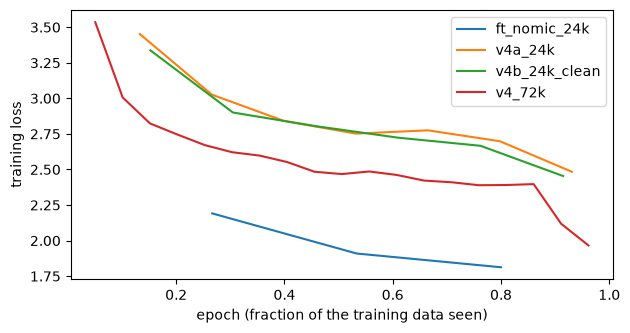

Note: v4 losses are higher partly because each comment now has 3 hard negatives and a bigger batch (a harder task), so compare MRR, not loss.


In [ ]:
# @title 13.2 Training loss curves (lower = the model separates right from wrong chunks better on training data)
plt.figure(figsize=(7, 3.5))
for t in ["ft_nomic_24k", "v4a_24k", "v4b_24k_clean", "v4_72k"]:
    p = f"{PROJECT}/models/{t}/train_log.json"
    if os.path.exists(p):
        log = [x for x in json.load(open(p)) if "loss" in x]
        plt.plot([x["epoch"] for x in log], [x["loss"] for x in log], label=t)
plt.xlabel("epoch (fraction of the training data seen)"); plt.ylabel("training loss"); plt.legend(); plt.show()
print("Note: v4 losses are higher partly because each comment now has 3 hard negatives and a bigger batch (a harder task), so compare MRR, not loss.")

**What we found (A)** (A100, 22 Nov, one seed; MRR)

| Run | comments | val | test | val + BM25 | test + BM25 |
|---|---|---|---|---|---|
| v2 (old recipe) | 24,000 | 0.562 | 0.545 | 0.583 | 0.559 (= v3) |
| v4a new recipe | 24,000 | 0.568 | 0.548 | 0.586 | 0.559 |
| v4b new recipe + cleaning | 24,000 → 20,983 | 0.570 | 0.543 | 0.588 | 0.553 |
| **v4** new recipe + cleaning | 71,972 → 63,222 | **0.581** | 0.546 | **0.601** | **0.560** |

- **The new recipe alone (v4a vs v2): +0.003 test.** That is inside the noise (~0.002–0.005 for one seed). 384 tokens and 3 hard negatives did not matter much.
- **Cleaning** dropped 12.2–12.6% of comments (P(plot) < 0.5). This matches the paper's ~12% off-topic estimate. It helped val by +0.002 and hurt test by −0.005: no real effect either way. The queue picked it for v4 because the rule was "higher val wins".
- **3× more data (v4 vs v4b): +0.011 on val but only +0.003 on test** (with BM25: +0.014 / +0.007). Against the old best v3, v4 + BM25 gains only +0.001 on test. This is the main finding of A. The val shows (Demon Slayer, Dr. Stone, Mob Psycho, Spy×Family) **are also in the training data**; the test shows are not. More comments from the training shows teach the model those shows' characters and events, which barely helps on shows it has never seen.
- Consequence: **val overrates trained models**. Choosing settings on val pushes us toward memorising seen shows. A better val would hold out whole shows. That is a weak point to state in the report.
- Cost on an A100: training v4a 11 min, v4b 9 min, v4 30 min (plus ~1–2 min each for mining hard negatives and evaluation).

## 14. B: modern models from 2025

Our base model and the paper's models are from 2019–2024. A fair report must compare against current models.
- **B1 Qwen3-Embedding** (Alibaba, June 2025; 0.6B / 4B / 8B parameters; top of the MTEB leaderboard), zero-shot. It takes an *instruction* in front of each comment.
- **B2 Qwen3-Embedding-0.6B fine-tuned** with exactly v2's recipe (24k comments, 256 tokens, 1 hard negative). Same data and recipe as v2, different base model, so the difference is the base model.
- **B3 rerankers**, zero-shot, on the top episodes of v3: `bge-reranker-v2-m3` (BAAI, 568M, a classic cross-encoder; top 10) and `Qwen3-Reranker-0.6B` (a small LLM asked "does this passage match the comment? yes/no"; the score is P(yes); top 5 only, because it reads every chunk of every candidate episode and top 10 took more than 3.5 h on an L4).

In [ ]:
show("zeroshot.py", 16, 34)
show("rerank.py", 36, 58)
if RUN_B:
    !python zeroshot.py test qwen3_emb_0.6b,qwen3_emb_4b,qwen3_emb_8b
    !python zeroshot.py val qwen3_emb_0.6b,qwen3_emb_4b,qwen3_emb_8b
    !python rerank.py ft_nomic_24k+bm25_w0.3 bge_rr_m3 chunks 10 test
    !python rerank.py ft_nomic_24k+bm25_w0.3 bge_rr_m3 chunks 10 val
    !python rerank.py ft_nomic_24k+bm25_w0.3 qwen3_rr_0.6b chunks 5 test
    !python train_biencoder.py 24000 qwen3_ft_24k --base Qwen/Qwen3-Embedding-0.6B --mini-batch 32
    !python fuse.py qwen3_ft_24k bm25_chunks

**`src/zeroshot.py`** lines 16–34

QWEN_Q = ("Instruct: Given a comment from a TV show discussion thread, retrieve the episode summary passage "
          "that the comment is about\nQuery:")
# name -> (hf id, max tokens, query prefix, doc prefix)
MODELS = {
    "minilm": ("sentence-transformers/all-MiniLM-L6-v2", 256, "", ""),
    "bge_base": ("BAAI/bge-base-en-v1.5", 512, "Represent this sentence for searching relevant passages: ", ""),
    "gte_modernbert": ("Alibaba-NLP/gte-modernbert-base", 8192, "", ""),
    "nomic_modernbert": ("nomic-ai/modernbert-embed-base", 8192, "search_query: ", "search_document: "),
    "bge_m3": ("BAAI/bge-m3", 8192, "", ""),
    # 2025 models (Qwen3-Embedding, June 2025): instruction in front of the query, nothing in front of documents
    "qwen3_emb_0.6b": ("Qwen/Qwen3-Embedding-0.6B", 8192, QWEN_Q, ""),
    "qwen3_emb_4b": ("Qwen/Qwen3-Embedding-4B", 8192, QWEN_Q, ""),
    "qwen3_emb_8b": ("Qwen/Qwen3-Embedding-8B", 8192, QWEN_Q, ""),
}

split = sys.argv[1] if len(sys.argv) > 1 else "test"
DEFAULT = ["minilm", "bge_base", "gte_modernbert", "nomic_modernbert", "bge_m3"]   # the v1 sweep
# batch sizes (queries, chunks, full summaries); the big Qwen models need small batches on a 24 GB GPU
BATCH = {"qwen3_emb_4b": (16, 8, 1), "qwen3_emb_8b": (8, 4, 1)}

**`src/rerank.py`** lines 36–58

class Qwen3Reranker:
    """Qwen3-Reranker scoring as described on its model card: prompt -> logits of 'yes' vs 'no'."""
    INSTRUCT = "Given a comment from a TV show discussion thread, judge whether the episode summary passage is what the comment talks about"
    PREFIX = ("<|im_start|>system\nJudge whether the Document meets the requirements based on the Query and the Instruct "
              "provided. Note that the answer can only be \"yes\" or \"no\".<|im_end|>\n<|im_start|>user\n")
    SUFFIX = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"

    def __init__(self, name):
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.tok = AutoTokenizer.from_pretrained(name, padding_side="left")
        self.model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16).cuda().eval()
        self.yes, self.no = self.tok.convert_tokens_to_ids("yes"), self.tok.convert_tokens_to_ids("no")

    @torch.no_grad()
    def predict(self, pairs, batch_size=32, **_):
        out = []
        for k in range(0, len(pairs), batch_size):
            texts = [f"{self.PREFIX}<Instruct>: {self.INSTRUCT}\n<Query>: {q}\n<Document>: {d}{self.SUFFIX}"
                     for q, d in pairs[k:k + batch_size]]
            b = self.tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to("cuda")
            last = self.model(**b, logits_to_keep=1).logits[:, -1, :]    # left padding: last position = answer slot
            out.append(torch.log_softmax(last[:, [self.no, self.yes]].float(), -1)[:, 1].cpu().numpy())
        return np.concatenate(out)

In [ ]:
# @title 14.1 Results: modern embedding models (zero-shot and fine-tuned) vs ours
display(table(["nomic_modernbert_chunks", "qwen3_emb_0.6b_chunks", "qwen3_emb_4b_chunks", "qwen3_emb_8b_chunks",
               "qwen3_emb_0.6b_full", "qwen3_emb_4b_full", "qwen3_emb_8b_full", "ft_nomic_24k", "qwen3_ft_24k"]))
# @title rerankers on the top episodes of v3
r = pd.read_csv(f"{PROJECT}/results/matching_results.csv"); r["split"] = r.split.fillna("test")
display(r[r.model.str.contains("_chunks_k")][["model", "split", "MRR", "top1", "secs"]].round(4))

,model,val MRR,test MRR,val MRR + BM25,test MRR + BM25
0,nomic_modernbert_chunks,0.498,0.476,NaN,NaN
1,qwen3_emb_0.6b_chunks,0.509,0.493,NaN,NaN
2,qwen3_emb_4b_chunks,0.523,0.534,NaN,NaN
3,qwen3_emb_8b_chunks,0.559,0.557,0.575,0.569
4,qwen3_emb_0.6b_full,0.442,0.403,NaN,NaN
5,qwen3_emb_4b_full,0.468,0.438,NaN,NaN
6,qwen3_emb_8b_full,0.501,0.493,NaN,NaN
7,ft_nomic_24k,0.562,0.545,0.583,0.559
8,qwen3_ft_24k,0.553,0.552,0.572,0.562


,model,split,MRR,top1,secs
0,ft_nomic_24k+gte_rr_chunks_k10,test,0.5595,0.4003,2443.9
45,ft_nomic_24k+bm25_w0.3+bge_rr_m3_chunks_k10,test,0.5124,0.3401,749.1
46,ft_nomic_24k+bm25_w0.3+bge_rr_m3_chunks_k10,val,0.5310,0.3628,344.9


### 14.2 v5: mix a fine-tuned model with a big zero-shot model

The two kinds of model make different mistakes: ours (v4) learned the training shows; Qwen3-8B never saw any of
our data. Adding their (per-comment standardised) scores is the simplest ensemble. **No weights are tuned:**
1 for each neural model, 0.3 for BM25 (the weight every single model picked on val in `fuse.py`).

In [ ]:
show("ensemble.py")
!python ensemble.py v4_72k+qwen3_emb_8b+bm25 v4_72k:1 qwen3_emb_8b_chunks:1 bm25_chunks:0.3

**`src/ensemble.py`**

"""Mix several matchers with fixed weights: score = sum_i w_i * z(score_i), per comment.

z() turns each model's scores for one comment into "how many standard deviations above this comment's average",
so models with different score scales can be added. No weights are tuned here: equal weight for the two neural
models, 0.3 for BM25 (the weight every single model picked on val in fuse.py).

Usage: python ensemble.py <name> <tag:weight> [<tag:weight> ...]
  python ensemble.py v4_72k+qwen3_emb_8b+bm25 v4_72k:1 qwen3_emb_8b_chunks:1 bm25_chunks:0.3
"""
import sys

import numpy as np

from common import append_result, evaluate, load_scores, load_split, save_scores
from fuse import z

name = sys.argv[1]
parts = [(p.rsplit(":", 1)[0], float(p.rsplit(":", 1)[1])) for p in sys.argv[2:]]
for split in ["val", "test"]:
    df = load_split(split)
    all_scores = [(load_scores(t, split), w) for t, w in parts]
    mixed = [sum(w * z(np.asarray(s[i], float)) for s, w in all_scores) for i in range(len(df))]
    save_scores(name, split, mixed)
    row = evaluate(df, mixed, name) | {"split": split}
    append_result(row)
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}, flush=True)

{'model': 'v4_72k+qwen3_emb_8b+bm25', 'MRR': np.float64(0.6202), 'top1': np.float64(0.4819), 'top3': np.float64(0.7011), 'MRR_demon_slayer_kimetsu_no_yaiba': np.float64(0.5354), 'MRR_dr_stone': np.float64(0.606), 'MRR_mob_psycho_100': np.float64(0.5272), 'MRR_spy_x_family': np.float64(0.7031), 'split': 'val'}


{'model': 'v4_72k+qwen3_emb_8b+bm25', 'MRR': np.float64(0.5977), 'top1': np.float64(0.4493), 'top3': np.float64(0.6886), 'MRR_arcane': np.float64(0.6905), 'MRR_attack_on_titan': np.float64(0.5381), 'MRR_kaguya_sama_love_is_war': np.float64(0.5857), 'MRR_legend_of_korra': np.float64(0.6375), 'split': 'test'}


**What we found (B)** (MRR; test = 4 unseen shows)

| Model | size | trained on our data? | val | test | test + BM25 |
|---|---|---|---|---|---|
| nomic ModernBERT (v1) | 149M | no | 0.498 | 0.476 | – |
| Qwen3-Emb-0.6B | 600M | no | 0.509 | 0.493 | – |
| Qwen3-Emb-4B | 4B | no | 0.523 | 0.534 | – |
| **Qwen3-Emb-8B** | 8B | no | 0.559 | **0.557** | **0.569** |
| ours v2 (nomic, 24k) | 149M | yes | 0.562 | 0.545 | 0.559 |
| Qwen3-Emb-0.6B fine-tuned (B2, v2 recipe, 24k) | 600M | yes | 0.553 | 0.552 | 0.562 |
| ours v4 (72k) | 149M | yes | 0.581 | 0.546 | 0.560 |
| **v5 = v4 + Qwen3-8B + BM25** (14.2) | 149M + 8B | mixed | **0.620** | **0.598** | – |

- **The 2025 model with no training is as good as our trained model on unseen shows.** Qwen3-Emb-8B gets 0.557 zero-shot vs our v2's 0.545. But it is 54× bigger. "Chunks" beat "whole summary" for every model again.
- **B2: a better base model helps more than more data.** The same 24k comments and recipe on Qwen3-0.6B give +0.006 test over nomic (0.552 vs 0.545; with BM25 0.562 vs 0.559). v4's 3× data gave +0.003.
- **B3 rerankers did not help.** bge-reranker-v2-m3 on v3's top 10 *lowered* MRR (test 0.512, val 0.531, vs 0.559 / 0.583). Rerankers trained on web search judge "is this passage relevant to the query", not "is this the episode the comment talks about". Qwen3-Reranker-0.6B on the top 5 (186,686 comment–chunk pairs) did not finish in 30 min on the A100 and was stopped, so there is no result. The 19 Nov gte reranker gave +0.001.
- **v5 (ensemble): test 0.598, top-1 0.449.** It is the best model on val too (0.620), so it is chosen by the val rule, not by looking at test. It is still below the paper's best (Longformer 0.611), but the gap went from 0.052 to 0.013. **Trade-off:** a comment now also goes through an 8B model (8B zero-shot: 118 s for all test comments + summaries on an A100). The "small and fast" claim only holds for v4 alone.

## 15. F: a fine-tuned plot classifier for the filter

The filter's weak part was "is this comment about plot at all?": frozen nomic vectors + logistic regression, AUC 0.855 on the test shows. With perfect labels the filter would catch 98% of spoilers instead of 68% (section 11).

**Change:** fine-tune the whole encoder with a 2-class head (cross-entropy), so it learns what "about plot" looks like.
- Data: hand-labelled comments of the 4 non-test shows (5,493). 15% held out as **dev** to choose the model; the 4 test shows are scored once at the end.
- Two candidates: `modernbert-embed-base` (149M, same backbone as our matcher) and `ModernBERT-large` (395M). The one with the higher **dev** AUC is used.
- Settings: 3 epochs, batch 32, lr 3e-5 (base) / 2e-5 (large, bigger models need smaller steps), 128 tokens, keep the best epoch by dev AUC.

In [ ]:
show("relevance.py")
if RUN_F:
    !python relevance.py nomic-ai/modernbert-embed-base relevance_ft_base 3e-5
    !python relevance.py answerdotai/ModernBERT-large relevance_ft_large 2e-5
rr = pd.read_csv(f"{PROJECT}/results/relevance_results.csv")
display(pd.concat([pd.DataFrame([{"model": "frozen nomic + logistic regression (19 Nov)", "dev_auc": None, "test_auc": 0.855}]),
                   rr[["model", "base", "dev_auc", "test_auc", "test_acc", "train_secs"]]]).round(3))

**`src/relevance.py`**

"""F: fine-tuned plot-relevance classifier ("is this comment about plot events at all?").

Before (filter_eval.py, 19 Nov): frozen nomic vectors + logistic regression, AUC 0.855 on the test shows.
That classifier is the filter's bottleneck (68% -> 98% spoilers caught with perfect labels).
Now: fine-tune the WHOLE encoder with a classification head (cross-entropy), so the model can learn
what "about plot" looks like instead of reusing vectors made for search.

Data: the hand-labelled relevance CSVs. Train ONLY on the 4 non-test shows; 15% of those comments are
held out as "dev" to pick the model (by dev AUC). The test shows are scored once at the end.

Usage
  python relevance.py nomic-ai/modernbert-embed-base relevance_ft_base
  python relevance.py answerdotai/ModernBERT-large   relevance_ft_large
Writes models/<tag>/, results/relevance_results.csv, results/relevance_pred__<tag>.parquet (test-show comments).
"""
import sys
import time

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.metrics import roc_auc_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer,
                          TrainingArguments)

from common import RESULTS, ROOT, warmup

TEST_SHOWS = {"attack_on_titan", "kaguya_sama_love_is_war", "legend_of_korra", "arcane"}
MAX_LEN = 128   # comments: median ~30 words; 128 tokens covers ~95% of them


def load_relevance():
    f = pd.concat([pd.read_csv(ROOT / f"data/raw/filtering/handlabeled/{s}.csv", header=None) for s in ["train", "dev", "test"]])
    f.columns = ["irrelevant", "comment", "show", "episode"]
    f["comment"] = f.comment.astype(str)
    f["label"] = 1 - f.irrelevant          # 1 = about plot
    return f.reset_index(drop=True)


@torch.no_grad()
def predict_relevance(model_dir, texts, batch=256):
    """P(about plot) for a list of comments, with a saved classifier."""
    tok = AutoTokenizer.from_pretrained(model_dir)
    m = AutoModelForSequenceClassification.from_pretrained(model_dir, dtype=torch.bfloat16).cuda().eval()
    order = np.argsort([len(t) for t in texts])   # similar lengths per batch = faster
    out = np.empty(len(texts))
    for k in range(0, len(texts), batch):
        idx = order[k:k + batch]
        b = tok([texts[i] for i in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to("cuda")
        out[idx] = torch.softmax(m(**b).logits.float(), -1)[:, 1].cpu().numpy()
    del m
    torch.cuda.empty_cache()
    return out


if __name__ == "__main__":
    base = sys.argv[1] if len(sys.argv) > 1 else "nomic-ai/modernbert-embed-base"
    tag = sys.argv[2] if len(sys.argv) > 2 else "relevance_ft"
    lr = float(sys.argv[3]) if len(sys.argv) > 3 else 3e-5
    out_dir = ROOT / "models" / tag

    f = load_relevance()
    pool = f[~f.show.isin(TEST_SHOWS)].sample(frac=1, random_state=0)
    n_dev = int(0.15 * len(pool))
    dev, tr = pool.iloc[:n_dev], pool.iloc[n_dev:]
    te = f[f.show.isin(TEST_SHOWS)].reset_index(drop=True)
    print(f"train {len(tr)} | dev {len(dev)} (same shows) | test {len(te)} (unseen shows)", flush=True)

    tok = AutoTokenizer.from_pretrained(base)
    enc = lambda d: Dataset.from_dict({"text": d.comment.tolist(), "label": d.label.tolist()}).map(
        lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])
    model = AutoModelForSequenceClassification.from_pretrained(base, num_labels=2)

    def metrics(p):
        prob = torch.softmax(torch.tensor(p.predictions).float(), -1)[:, 1].numpy()
        return {"auc": roc_auc_score(p.label_ids, prob), "acc": ((prob > 0.5) == p.label_ids).mean()}

    targs = TrainingArguments(
        output_dir=str(out_dir / "ckpt"), num_train_epochs=3, per_device_train_batch_size=32, per_device_eval_batch_size=128,
        learning_rate=lr, weight_decay=0.01, **warmup(0.1), bf16=torch.cuda.is_bf16_supported(),
        eval_strategy="epoch", save_strateg

,model,dev_auc,test_auc,base,test_acc,train_secs
0,frozen nomic + logistic regression (19 Nov),None,0.855,NaN,NaN,NaN
0,relevance_ft_base,0.929383,0.884,nomic-ai/modernbert-embed-base,0.792,146.0
1,relevance_ft_large,0.9224,0.870,answerdotai/ModernBERT-large,0.788,230.0
2,relevance_ft,0.9267,0.882,nomic-ai/modernbert-embed-base,0.797,88.0


In [ ]:
# @title 15.1 The filter with the new classifier (and the best matcher)
if RUN_F:
    !python filter_eval.py "{BEST_MATCHER}" {BEST_REL}
fr = pd.read_csv(f"{PROJECT}/results/filter_results.csv")
fr["relevance_model"] = fr.get("relevance_model", pd.Series(index=fr.index, dtype=object)).fillna("lr")
cols = ["system", "matching_model", "relevance_model", "spoilers_hidden_at_10pct_safe_hidden", "spoilers_hidden_at_5pct_safe_hidden", "AUC", "safe_plot_comments_hidden"]
display(fr[fr.system != "hide_nothing"][cols].dropna(subset=["spoilers_hidden_at_10pct_safe_hidden"]).round(3))

,system,matching_model,relevance_model,spoilers_hidden_at_10pct_safe_hidden,spoilers_hidden_at_5pct_safe_hidden,AUC,safe_plot_comments_hidden
5,classic_detector,ft_nomic_24k+bm25_w0.3,lr,0.372,0.227,0.804,0.735
6,progress_aware,ft_nomic_24k+bm25_w0.3,lr,0.680,0.540,0.890,0.037
7,progress_aware_oracle_rel,ft_nomic_24k+bm25_w0.3,lr,0.978,0.897,0.982,0.129
9,classic_detector,ft_nomic_24k+bm25_w0.3,relevance_ft_base,0.440,0.278,0.826,0.743
10,progress_aware,ft_nomic_24k+bm25_w0.3,relevance_ft_base,0.707,0.558,0.905,0.055
11,progress_aware_oracle_rel,ft_nomic_24k+bm25_w0.3,relevance_ft_base,0.978,0.897,0.982,0.129
13,classic_detector,v4_72k+bm25_w0.3,relevance_ft_base,0.440,0.278,0.826,0.743
14,progress_aware,v4_72k+bm25_w0.3,relevance_ft_base,0.705,0.558,0.905,0.050
15,progress_aware_oracle_rel,v4_72k+bm25_w0.3,relevance_ft_base,0.979,0.901,0.982,0.121
17,classic_detector,v4_72k+qwen3_emb_8b+bm25,relevance_ft_base,0.440,0.278,0.826,0.743


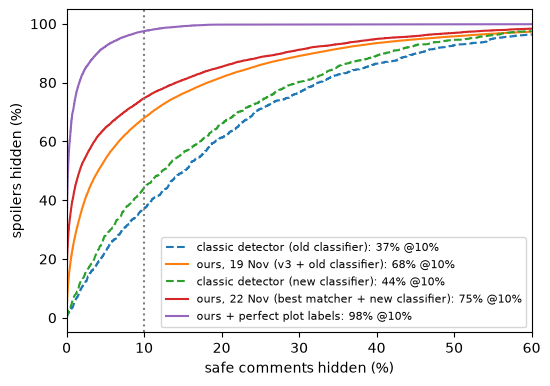

In [ ]:
# @title 15.2 Trade-off curves: old vs new plot classifier
from sklearn.metrics import roc_curve
plt.figure(figsize=(6, 4.2))
curves = [("filter_sim__ft_nomic_24k_bm25_w0.3.parquet", "classic_detector", "classic detector (old classifier)"),
          ("filter_sim__ft_nomic_24k_bm25_w0.3.parquet", "progress_aware", "ours, 19 Nov (v3 + old classifier)"),
          (f"filter_sim__{BEST_MATCHER.replace('+', '_')}__{BEST_REL}.parquet", "classic_detector", "classic detector (new classifier)"),
          (f"filter_sim__{BEST_MATCHER.replace('+', '_')}__{BEST_REL}.parquet", "progress_aware", "ours, 22 Nov (best matcher + new classifier)"),
          (f"filter_sim__{BEST_MATCHER.replace('+', '_')}__{BEST_REL}.parquet", "progress_aware_oracle_rel", "ours + perfect plot labels")]
for f, col, label in curves:
    p = f"{PROJECT}/results/{f}"
    if not os.path.exists(p): continue
    sim = pd.read_parquet(p); fpr, tpr, _ = roc_curve(sim.spoiler, sim[col]); k = np.searchsorted(fpr, .10)
    plt.plot(fpr * 100, tpr * 100, label=f"{label}: {tpr[k]:.0%} @10%", ls="--" if "classic" in label else "-")
plt.axvline(10, ls=":", c="gray"); plt.xlim(0, 60)
plt.xlabel("safe comments hidden (%)"); plt.ylabel("spoilers hidden (%)"); plt.legend(fontsize=8); plt.show()

**What we found (F)**

| Plot classifier | dev AUC | test AUC (unseen shows) | train time |
|---|---|---|---|
| frozen nomic + logistic regression (19 Nov) | – | 0.855 | seconds |
| **fine-tuned modernbert-embed-base** | **0.929** | **0.884** | 2.5 min (laptop) |
| fine-tuned ModernBERT-large | 0.922 | 0.870 | 4 min (L4) |

The base model wins on dev, so it is used. The large model is worse on both splits, maybe because 4.7k training comments are too few for 395M parameters. (Its row comes from the run log; its saved predictions were lost when a VM was reclaimed.)

**The filter** (spoilers hidden when 10% of safe comments are hidden; 206,968 simulated viewer–comment pairs)

| Matcher + plot classifier | ours | classic detector | ours with perfect plot labels |
|---|---|---|---|
| v3 + logistic regression (19 Nov) | 68.0% | 37.2% | 97.8% |
| v3 + fine-tuned classifier | 70.7% | 44.0% | 97.8% |
| v4 + BM25 + fine-tuned classifier | 70.5% | 44.0% | 97.9% |
| **v5 + fine-tuned classifier** | **71.1%** | 44.0% | 98.2% |

- The new classifier helps both systems (+2.7 points for ours, +6.8 for the classic detector, which leans on it more). Ours still hides **27 points more** spoilers than the classic detector at the same cost.
- A much better matcher (v3 → v5, +0.04 MRR) moves the filter by only +0.4 points. **The plot classifier is still the bottleneck:** perfect plot labels would give 98%. The next gains are in F2/F3, not in matching.

## 16. v6: a small two-stage matcher that beats the paper (22–23 Nov)

**Goal:** beat the paper's best (Longformer, test MRR 0.611) with a model **under 300M parameters**.
Longformer-base itself has ~149M, so this is a fair same-size comparison.

**Idea: two stages.**
```
comment ─► STAGE 1 (fast, all episodes): bi-encoder (149M) + BM25 → score every episode → keep the top K
        ─► STAGE 2 (precise, K episodes): reranker (149M) reads "comment + chunk" TOGETHER,
           for the M best chunks of each kept episode → episode score = its best chunk (MaxP)
        ─► final = z(reranker) + a · z(stage 1)        (z = standardised over the K episodes)
```
- **Why stage 2 helps.** The bi-encoder turns the comment and a chunk into one vector each and compares the
  vectors: details get lost. A **cross-encoder** puts both texts into one input, so every comment word can attend
  to every summary word ("the guy with the scar" ↔ "Zuko"). It is slower, so it only re-reads the top K.
- **Size:** 149M + 149M = **298M**. The reranker starts from `Alibaba-NLP/gte-reranker-modernbert-base`
  (a ModernBERT already trained to rerank web search results). Zero-shot it did not help (section 10, B3);
  here it is **fine-tuned on our task**.

**G1: honest val.** The 4 val shows were also in the training data (8,202 comments), so val rewarded memorising
(lesson from A). From v6 on, **nothing is trained on the val shows**, and K, M and a are picked on val only.

**Training the reranker (listwise).** For each training comment, a group of 8 chunks:
- 1 positive = the chunk of the correct episode that the stage-1 bi-encoder finds most similar;
- 7 hard negatives = the best chunk of each of the 7 highest-ranked **wrong** episodes (same show, similar text).

The model scores the 8 chunks, softmax over the group, loss = −log P(positive) (cross-entropy).
Training comments are **not** the ones the bi-encoder was trained on (on those it is too good, so its "hard"
negatives would be too easy). 1 epoch, lr 2e-5, 16 groups per step, 384 tokens, bf16.
Training sizes 24k and 48k comments were compared on val; the winner got 3 seeds.

In [ ]:
show("train_reranker.py")
show("combine_rerank.py")
if RUN_V6:
    !python train_biencoder.py 24000 v6_bi --max-len 384 --negs 3 --batch 128 --mini-batch 64 --exclude-shows val
    !python fuse.py v6_bi bm25_chunks v6_first
    !python train_reranker.py v6_bi v6_first v6_rr24_s0 --n 24000 --seed 0
    for s in [0, 1, 2]:
        !python train_reranker.py v6_bi v6_first v6_rr48_s{s} --n 48000 --seed {s}
    for t in ["v6_rr24_s0", "v6_rr48_s0", "v6_rr48_s1", "v6_rr48_s2"]:
        !python combine_rerank.py v6_first {t} {t}
    !python combine_rerank.py v6_first v6_3seeds v6_rr48_s0 v6_rr48_s1 v6_rr48_s2
    !python train_reranker.py v6_bi v6_first gte_rr_zeroshot --no-train   # same pipeline, reranker NOT fine-tuned
    !python combine_rerank.py v6_first v6_gte_zeroshot gte_rr_zeroshot

**`src/train_reranker.py`**

"""Stage 2: fine-tune a small cross-encoder reranker, then score the top episodes of val and test.

Full matcher (both models together < 300M parameters):
  stage 1  bi-encoder (149M) + BM25 score every episode of the show -> keep the top K episodes
  stage 2  this reranker (149M) reads (comment, chunk) TOGETHER for the best M chunks of each kept episode
           (best = most similar to the comment under the bi-encoder); episode score = best chunk score (MaxP)

Why a cross-encoder: the bi-encoder turns comment and chunk into one vector EACH, then compares the vectors,
so details get lost. A cross-encoder puts both texts in one input, so every comment word can attend to every
summary word ("the guy with the scar" <-> "Zuko"). It is slower, so it only sees the top K episodes.

Training data (built automatically, listwise):
  for each training comment, a group of G chunks: 1 positive + G-1 hard negatives
    positive  = the chunk of the correct episode that the bi-encoder finds most similar
    negatives = the best chunk of each of the G-1 highest-ranked WRONG episodes (same show, similar text)
  the model scores the G chunks, softmax over the group, loss = -log P(positive)   (cross-entropy)
Training comments never come from the val shows (val stays honest) and are not the comments the bi-encoder
was trained on (on those it is too good, so its "hard" negatives would be too easy).

Output: models/<tag>/ and results/scores/<tag>__{val,test}.pkl = reranker score of the top M chunks of the top K
episodes for every comment. combine_rerank.py then picks K, M and the stage-1 weight on val.

Usage
  python train_reranker.py v6_bi v6_first v6_rr_s0 --seed 0
  python train_reranker.py v6_bi v6_first gte_rr_zeroshot --no-train          # same pipeline, untrained reranker
"""
import argparse
import json
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

from common import ROOT, SCORES, chunk_text, load_scores, load_split, load_summaries

QP, DP = "search_query: ", "search_document: "  # prompts of the nomic bi-encoder

ap = argparse.ArgumentParser()
ap.add_argument("bi", help="stage-1 bi-encoder (models/<bi>), used to pick chunks and mine negatives")
ap.add_argument("first", help="stage-1 score tag for val/test (e.g. bi-encoder + BM25 mix)")
ap.add_argument("tag", help="name of the saved reranker / score files")
ap.add_argument("--base", default="Alibaba-NLP/gte-reranker-modernbert-base", help="starting checkpoint (149M)")
ap.add_argument("--n", type=int, default=24000, help="training comments")
ap.add_argument("--group", type=int, default=8, help="chunks per training group: 1 positive + group-1 negatives")
ap.add_argument("--batch", type=int, default=16, help="groups per optimizer step")
ap.add_argument("--micro", type=int, default=4, help="groups per forward pass (memory only)")
ap.add_argument("--epochs", type=float, default=1)
ap.add_argument("--lr", type=float, default=2e-5)
ap.add_argument("--max-len", type=int, default=384, help="tokens for comment + chunk")
ap.add_argument("--cap", type=int, default=15000, help="max comments per show")
ap.add_argument("--seed", type=int, default=0)
ap.add_argument("--kmax", type=int, default=15, help="episodes re-scored per comment at test time (max tried)")
ap.add_argument("--mmax", type=int, default=4, help="chunks re-scored per episode (max tried)")
ap.add_argument("--splits", default="val,test")
ap.add_argument("--no-train", action="store_true", help="skip training: score with the base checkpoint")
args = ap.parse_args()
print("config:", vars(args), flush=True)
torch.manual_seed(args.seed)
rng = np.random.default_rng(args.seed)
OUT = ROOT / "models" / args.tag
summ = load_summaries()

# ---- stage-1 bi-encoder: chunk embeddings per show
bi = SentenceT

**`src/combine_rerank.py`**

"""Turn reranker chunk scores (train_reranker.py) into final episode rankings.

For each comment, the top K episodes of stage 1 get
    final = z(rerank) + a * z(stage 1)          (z = standardised over those K episodes)
    rerank = best score among the episode's top M chunks (MaxP); with several reranker tags (seeds) we average
             their z-scores first
The other episodes stay below them, in stage-1 order.
K (episodes re-scored), M (chunks per episode) and a (how much stage 1 still counts) are picked on VAL only;
test is scored once with the winner.

Usage: python combine_rerank.py <stage-1 tag> <out name> <rr tag> [<rr tag> ...]
  python combine_rerank.py v6_first v6 v6_rr_s0
"""
import pickle
import sys

import numpy as np

from common import SCORES, append_result, evaluate, load_scores, load_split, save_scores
from fuse import z

KS, MS, AS = [5, 10, 15], [1, 2, 4], [0.0, 0.25, 0.5, 1.0, 2.0]


def build(first, rrs, K, M, a):
    out = []
    for i, f in enumerate(first):
        f = np.asarray(f, float)
        top = np.argsort(-f)[:K]
        r = np.mean([z([max(rr[i][int(j)][:M]) for j in top]) for rr in rrs], axis=0)
        s = f - 1e6
        s[top] = r + a * z(f[top])
        out.append(s)
    return out


if __name__ == "__main__":
    first_tag, name, rr_tags = sys.argv[1], sys.argv[2], sys.argv[3:]
    data = {sp: (load_split(sp), load_scores(first_tag, sp), [pickle.load(open(SCORES / f"{t}__{sp}.pkl", "rb")) for t in rr_tags])
            for sp in ["val", "test"]}
    df, first, rrs = data["val"]
    kmax = max(len(d) for d in rrs[0])
    KS = [k for k in KS if k <= kmax]
    grid = {(K, M, a): evaluate(df, build(first, rrs, K, M, a))["MRR"] for K in KS for M in MS for a in AS}
    for K in KS:
        print(f"K={K:<3}" + "  ".join(f"M={M} " + " ".join(f"{grid[K, M, a]:.3f}" for a in AS) for M in MS))
    K, M, a = max(grid, key=grid.get)
    print(f"best on val: K={K} M={M} a={a} (val MRR {grid[K, M, a]:.4f}); a values in each row: {AS}", flush=True)
    for split in ["val", "test"]:
        df, first, rrs = data[split]
        s = build(first, rrs, K, M, a)
        save_scores(name, split, s)
        row = evaluate(df, s, name) | {"split": split, "K": K, "M": M, "a": a}
        append_result(row)
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}, flush=True)

In [ ]:
# @title 16.1 Results (val = honest now; test = 4 unseen shows), with 95% bootstrap ranges on test
r = pd.read_csv(f"{PROJECT}/results/matching_results.csv"); r["split"] = r.split.fillna("test")
from common import load_scores, load_split, load_summaries
_summ, _test = load_summaries(), load_split("test")
def rr_of(tag):
    return np.array([1 / (1 + (np.asarray(s, float) > np.asarray(s, float)[_summ[sh][0].index(ep)]).sum())
                     for (sh, ep), s in zip(_test[["show", "episode"]].itertuples(index=False), load_scores(tag, "test"))])
_rng = np.random.default_rng(0); _idx = [_rng.integers(0, len(_test), len(_test)) for _ in range(2000)]
NAMES = {"v6_bi": "stage 1 alone: bi-encoder (val shows left out)", "v6_first": "stage 1: bi-encoder + BM25",
         "v6_gte_zeroshot": "+ reranker, NOT fine-tuned", "v6_rr24_s0": "+ fine-tuned reranker, 24k, seed 0",
         "v6_rr48_s0": "+ fine-tuned reranker, 48k, seed 0", "v6_rr48_s1": "+ fine-tuned reranker, 48k, seed 1",
         "v6_rr48_s2": "+ fine-tuned reranker, 48k, seed 2", "v6_3seeds": "3 rerankers averaged (3 × 149M, not < 300M)"}
rows = []
for t, name in NAMES.items():
    v, te = r[(r.model == t) & (r.split == "val")], r[(r.model == t) & (r.split == "test")]
    if len(te) == 0: continue
    b = [rr_of(t)[i].mean() for i in _idx[:500]]
    rows.append({"model": name, "val MRR": v.MRR.iloc[0] if len(v) else None, "test MRR": te.MRR.iloc[0],
                 "test 95% range": f"{np.percentile(b, 2.5):.3f}–{np.percentile(b, 97.5):.3f}", "test top-1": te.top1.iloc[0],
                 "K, M, a (picked on val)": "" if pd.isna(te.get("K", pd.Series([None])).iloc[0]) else f"{int(te.K.iloc[0])}, {int(te.M.iloc[0])}, {te.a.iloc[0]}"})
display(pd.DataFrame(rows).round(3))
s = r[r.model.isin(["v6_rr48_s0", "v6_rr48_s1", "v6_rr48_s2"])]
print("48k reranker over 3 seeds:", {sp: f"{g.MRR.mean():.3f} ± {g.MRR.std():.3f}" for sp, g in s.groupby("split")}, "| paper best 0.611")

,model,val MRR,test MRR,test 95% range,test top-1,"K, M, a (picked on val)"
0,stage 1 alone: bi-encoder (val shows left out),0.554,0.544,0.530–0.557,0.394,
1,stage 1: bi-encoder + BM25,0.573,0.556,0.541–0.568,0.406,
2,"+ reranker, NOT fine-tuned",0.610,0.600,0.587–0.612,0.455,"15, 4, 1.0"
3,"+ fine-tuned reranker, 24k, seed 0",0.639,0.636,0.622–0.650,0.507,"15, 4, 1.0"
4,"+ fine-tuned reranker, 48k, seed 0",0.641,0.637,0.624–0.650,0.507,"15, 4, 1.0"
5,"+ fine-tuned reranker, 48k, seed 1",0.629,0.639,0.625–0.653,0.510,"15, 4, 1.0"
6,"+ fine-tuned reranker, 48k, seed 2",0.634,0.635,0.621–0.648,0.505,"15, 4, 1.0"
7,"3 rerankers averaged (3 × 149M, not < 300M)",0.639,0.641,0.627–0.654,0.511,"15, 4, 1.0"


48k reranker over 3 seeds: {'test': '0.637 ± 0.002', 'val': '0.635 ± 0.006'} | paper best 0.611


In [ ]:
# @title 16.2 How K (episodes re-read), M (chunks per episode) and a (stage-1 weight) were chosen: val MRR grid
print(open(f"{PROJECT}/results/logs_v6/c_rr48_s0.log").read().split("best on val")[0])
print("each row: a =", [0.0, 0.25, 0.5, 1.0, 2.0], "| more episodes and more chunks help; stage 1 still counts (a = 1)")

K=5  M=1 0.572 0.588 0.594 0.603 0.597  M=2 0.593 0.605 0.608 0.609 0.600  M=4 0.602 0.614 0.617 0.614 0.603
K=10 M=1 0.566 0.590 0.603 0.614 0.609  M=2 0.593 0.615 0.622 0.624 0.616  M=4 0.605 0.625 0.633 0.633 0.618
K=15 M=1 0.554 0.583 0.602 0.613 0.614  M=2 0.586 0.615 0.623 0.629 0.622  M=4 0.596 0.620 0.632 0.641 0.626

each row: a = [0.0, 0.25, 0.5, 1.0, 2.0] | more episodes and more chunks help; stage 1 still counts (a = 1)


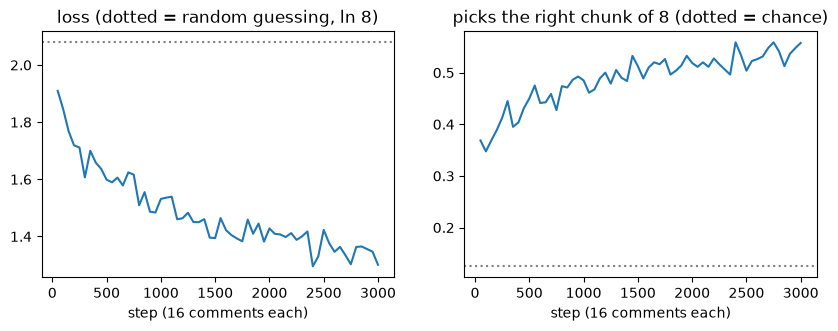

In [ ]:
# @title 16.3 Reranker training curve (seed 2): loss and accuracy on the 8-way choice
log = pd.DataFrame(json.load(open(f"{PROJECT}/models/v6_rr48_s2/train_log.json")))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(log.step, log.loss); ax[0].axhline(np.log(8), ls=":", c="gray"); ax[0].set_title("loss (dotted = random guessing, ln 8)")
ax[1].plot(log.step, log.acc); ax[1].axhline(1 / 8, ls=":", c="gray"); ax[1].set_title("picks the right chunk of 8 (dotted = chance)")
for a in ax: a.set_xlabel("step (16 comments each)")
plt.show()

In [ ]:
# @title 16.4 Speed on the laptop GPU (RTX 4050), all 3,105 test comments
sp = json.load(open(f"{PROJECT}/results/speed.json"))
sp |= json.load(open(f"{PROJECT}/results/speed_v6_K15_M4.json"))
fast = json.load(open(f"{PROJECT}/results/speed_v6_K5_M1.json"))
rows = [{"model": "v4-style bi-encoder alone (149M)", "all test comments (s)": sp["ours_all_test_comments_secs"]},
        {"model": f"v6, K={sp['v6_K']}, M={sp['v6_M']} (298M, the accurate setting)", "all test comments (s)": sp["v6_all_test_secs"]}]
if fast:
    rows.append({"model": f"v6, K={fast['v6_K']}, M={fast['v6_M']} (298M, fast setting)", "all test comments (s)": fast["v6_all_test_secs"]})
rows.append({"model": "Longformer cross-encoder (paper's best, estimate)", "all test comments (s)": sp["longformer_all_test_secs_est"]})
d = pd.DataFrame(rows); d["comments / s"] = 3105 / d["all test comments (s)"]
d["× faster than Longformer"] = sp["longformer_all_test_secs_est"] / d["all test comments (s)"]
display(d.round(1))

,model,all test comments (s),comments / s,× faster than Longformer
0,v4-style bi-encoder alone (149M),11.9,261.8,4597.7
1,"v6, K=15, M=4 (298M, the accurate setting)",1256.4,2.5,43.4
2,"v6, K=5, M=1 (298M, fast setting)",127.3,24.4,428.4
3,"Longformer cross-encoder (paper's best, estimate)",54531.1,0.1,1.0


### 16.5 What we found (v6)

| | test MRR | val MRR |
|---|---|---|
| stage 1 alone (bi-encoder + BM25, val shows left out) | 0.556 | 0.573 |
| + reranker **not** fine-tuned | 0.600 | 0.610 |
| + fine-tuned reranker, 48k, seeds 0 / 1 / 2 | **0.637 / 0.639 / 0.635** | 0.641 / 0.629 / 0.634 |
| 3 seeds, mean ± std | **0.637 ± 0.002** | 0.635 ± 0.006 |
| 3 rerankers averaged (3 × 149M, not < 300M) | 0.641 | 0.639 |
| paper's best (Longformer) | 0.611 | – |

- **Goal reached.** Every single reranker (298M in total) beats 0.611, and each test 95% range lies above it.
  Top-1 accuracy is ~51%: half the time the right episode is ranked first, among 9–62 episodes (test shows).
- **Fine-tuning is what matters:** the same reranker without training gives 0.600; training adds +0.035.
- **Honest val works:** val and test now agree (0.634 vs 0.635 for seed 2). Before G1, val was ~0.02–0.04 too high.
- 24k vs 48k training comments: 0.636 vs 0.637, i.e. no real difference. Seeds differ by ±0.002.
- K=15, M=4, a=1 won on val for every run: read more episodes and more chunks, and keep stage 1 in the score.
- **Speed (laptop RTX 4050, 3,105 test comments):** accurate setting K=15, M=4: 21 min (~43× faster than the
  Longformer estimate, 15 h). Fast setting K=5, M=1: 2 min (~430× faster), test MRR 0.591. K=10, M=2: 0.620.
- **Full filter** (with the F plot classifier), at 10% of safe comments hidden: v6 hides **74.7%** of spoilers
  (v5 71.1%, classic detector 44.0%, perfect plot labels 97.5%). The plot classifier is still the bottleneck.

**Weak points (honest):**
- The paper's 0.611 is one number from their paper; we cannot run a paired test against their predictions.
- Our model is 298M, about 2× Longformer-base (~149M). We win on accuracy and speed, not on size.
- v6 is ~100× slower than v4 alone (12 s), because the reranker reads 60 pairs per comment.
- Only one bi-encoder (stage 1) seed. The reranker has 3 seeds.
- One dataset only (anime / cartoon shows from Reddit). Other domains are untested.

## 17. Error analysis, one more try at the plot classifier, and the demo (25 Nov)

Three things, none of them a new matcher (v6 stays the best):
1. **Error analysis (17.1):** where does v6 go wrong? Numbers for the whole test set, and 60 wrong predictions read by hand.
2. **F2 (17.2):** can the matcher help the "is it about the story?" classifier, the filter's weakest part?
3. **Demo (17.3):** the full filter on any comment (`demo.py`), and a web page with 200 real test comments (`report/demo.html`).

### 17.1 Error analysis

`error_analysis.py` takes v6's test scores and asks: which shows are hard, how far off is a wrong top guess, do short comments fail more?
It also saves a fixed random sample of 60 wrong predictions (`results/error_sample.csv`). We read those by hand and gave each one a category (column `category`).

In [ ]:
show("error_analysis.py")
!python error_analysis.py v6_rr48_s2

**`src/error_analysis.py`**

"""Error analysis for the main matcher (v6_rr48_s2) on the test set.

Questions:
  1. Per show: where does the model do well or badly?
  2. When it is wrong, how far is its top guess from the right episode?
     (a guess 1 episode away is a "near miss"; for the filter it often does not matter much)
  3. Do short comments fail more often?
  4. A random sample of 60 wrong comments to read by hand (results/error_sample.csv). Our hand-made category for
     each one is kept in results/error_labels_by_hand.csv and joined in here, so re-running never loses it.
Usage: python error_analysis.py [model tag]
"""
import sys

import numpy as np
import pandas as pd

from common import RESULTS, load_scores, load_split, load_summaries

TAG = sys.argv[1] if len(sys.argv) > 1 else "v6_rr48_s2"
summ = load_summaries()
test = load_split("test")
scores = load_scores(TAG, "test")

rows = []
for (show, ep, comment), s in zip(test[["show", "episode", "comment"]].itertuples(index=False), scores):
    s = np.asarray(s, float)
    eps = summ[show][0]
    gold = eps.index(ep)
    pred = int(s.argmax())
    rank = 1 + int((s > s[gold]).sum())
    rows.append(dict(show=show, n_eps=len(eps), gold=ep, pred=eps[pred], rank=rank, rr=1 / rank,
                     offset=pred - gold, words=len(comment.split()), comment=comment))
df = pd.DataFrame(rows)
df["correct"] = df["rank"] == 1

print(f"model {TAG}: MRR {df.rr.mean():.3f}  top-1 {df.correct.mean():.3f}  top-3 {(df['rank'] <= 3).mean():.3f}  "
      f"top-5 {(df['rank'] <= 5).mean():.3f}")

# 1. per show
per_show = df.groupby("show").agg(comments=("rr", "size"), episodes=("n_eps", "first"), MRR=("rr", "mean"),
                                  top1=("correct", "mean")).round(3)
per_show["random_MRR"] = [round(np.mean([1 / r for r in range(1, n + 1)]), 3) for n in per_show.episodes]
print("\nper show\n", per_show.to_string())

# 2. how far off is the top guess when it is wrong
wrong = df[~df.correct]
dist = wrong.offset.abs()
bins = pd.cut(dist, [0, 1, 2, 5, 1000], labels=["1 episode away", "2 away", "3-5 away", "6+ away"])
off = bins.value_counts(normalize=True).reindex(["1 episode away", "2 away", "3-5 away", "6+ away"]).round(3)
print(f"\nwrong top guesses: {len(wrong)} ({len(wrong) / len(df):.1%} of comments)")
print("distance of the wrong guess:\n", off.to_string())
print(f"guess is a LATER episode than the right one: {(wrong.offset > 0).mean():.1%}")

# 3. comment length
df["length"] = pd.cut(df.words, [0, 10, 20, 40, 10000], labels=["1-10 words", "11-20", "21-40", "41+"])
by_len = df.groupby("length", observed=True).agg(comments=("rr", "size"), MRR=("rr", "mean"), top1=("correct", "mean")).round(3)
print("\nby comment length\n", by_len.to_string())

# save tables + a fixed random sample of wrong comments for reading by hand
per_show.to_csv(RESULTS / "error_per_show.csv")
by_len.to_csv(RESULTS / "error_by_length.csv")
off.to_csv(RESULTS / "error_distance.csv")
sample = wrong.sample(60, random_state=0)[["show", "gold", "pred", "rank", "words", "comment"]]
labels = RESULTS / "error_labels_by_hand.csv"
if labels.exists() and TAG == "v6_rr48_s2":
    lab = pd.read_csv(labels)
    assert (lab.comment.values == sample.comment.values).all(), "the sample changed; the hand labels no longer match"
    sample["category"] = lab.category.values
    cat = sample.category.value_counts().rename("comments").to_frame()
    cat["share"] = (cat.comments / len(sample)).round(2)
    cat.to_csv(RESULTS / "error_categories.csv")
    print("\nkinds of errors (60 read by hand)\n", cat.to_string())
sample.to_csv(RESULTS / "error_sample.csv", index=False)
df.drop(columns="comment").to_csv(RESULTS / f"predictions__{TAG}.csv", index=False)

model v6_rr48_s2: MRR 0.635  top-1 0.505  top-3 0.718  top-5 0.798

per show
                          comments  episodes    MRR   top1  random_MRR
show                                                                 
arcane                        246         9  0.710  0.573       0.314
attack_on_titan              1244        62  0.588  0.461       0.076
kaguya_sama_love_is_war       248        19  0.610  0.468       0.187
legend_of_korra              1367        27  0.669  0.540       0.144



wrong top guesses: 1536 (49.5% of comments)
distance of the wrong guess:
 offset
1 episode away    0.197
2 away            0.117
3-5 away          0.177
6+ away           0.509
guess is a LATER episode than the right one: 37.4%

by comment length
             comments    MRR   top1
length                            
1-10 words       549  0.509  0.370
11-20            559  0.615  0.485
21-40            775  0.656  0.535
41+             1222  0.688  0.556

kinds of errors (60 read by hand)
                                           comments  share
category                                                 
Next/previous or a very similar episode         16   0.27
Too short or vague                              14   0.23
Small detail not in the summary                  9   0.15
General reaction, little story                   9   0.15
About older episodes or the whole season         7   0.12
A guess or question about the future             5   0.08


In [ ]:
# @title 17.1b The 60 wrong predictions, sorted by hand
es = pd.read_csv(f"{PROJECT}/results/error_sample.csv")
display(pd.read_csv(f"{PROJECT}/results/error_categories.csv", index_col=0))
for cat, g in es.groupby("category"):
    print(f"\n== {cat} ({len(g)})")
    for r in g.head(3).itertuples():
        print(f"  {r.show[:16]:16s} right ep {r.gold:>2}, guessed {r.pred:>2}: {r.comment[:110]}")

,comments,share
category,,
Next/previous or a very similar episode,16,0.27
Too short or vague,14,0.23
Small detail not in the summary,9,0.15
"General reaction, little story",9,0.15
About older episodes or the whole season,7,0.12
A guess or question about the future,5,0.08



== A guess or question about the future (5)
  legend_of_korra  right ep 18, guessed 41: So Korra lost her memory, right? Maybe Katara could be contacted to try to restore her memory in the way she d
  attack_on_titan  right ep 83, guessed 45: 4 titan shifters in the same room with another right outside and two Ackermans, shit is about to get crazy
  attack_on_titan  right ep 80, guessed 76: Someone please make a poll how many believe Eren (exterminate non-Eldian) or Zeke (exterminate all Eldian) or 

== About older episodes or the whole season (7)
  legend_of_korra  right ep 21, guessed 48: Does anyone know if Raava has that horse-shoe like mark on her? After the spiritual cleansing or whatever, the
  legend_of_korra  right ep 36, guessed 41: I'd like to point out that this is the first time we've seen the asphyxiation technique in action, but not the
  attack_on_titan  right ep 86, guessed 65: Last episode really set this one up nicely. Connie has to kill his friends and get his hand

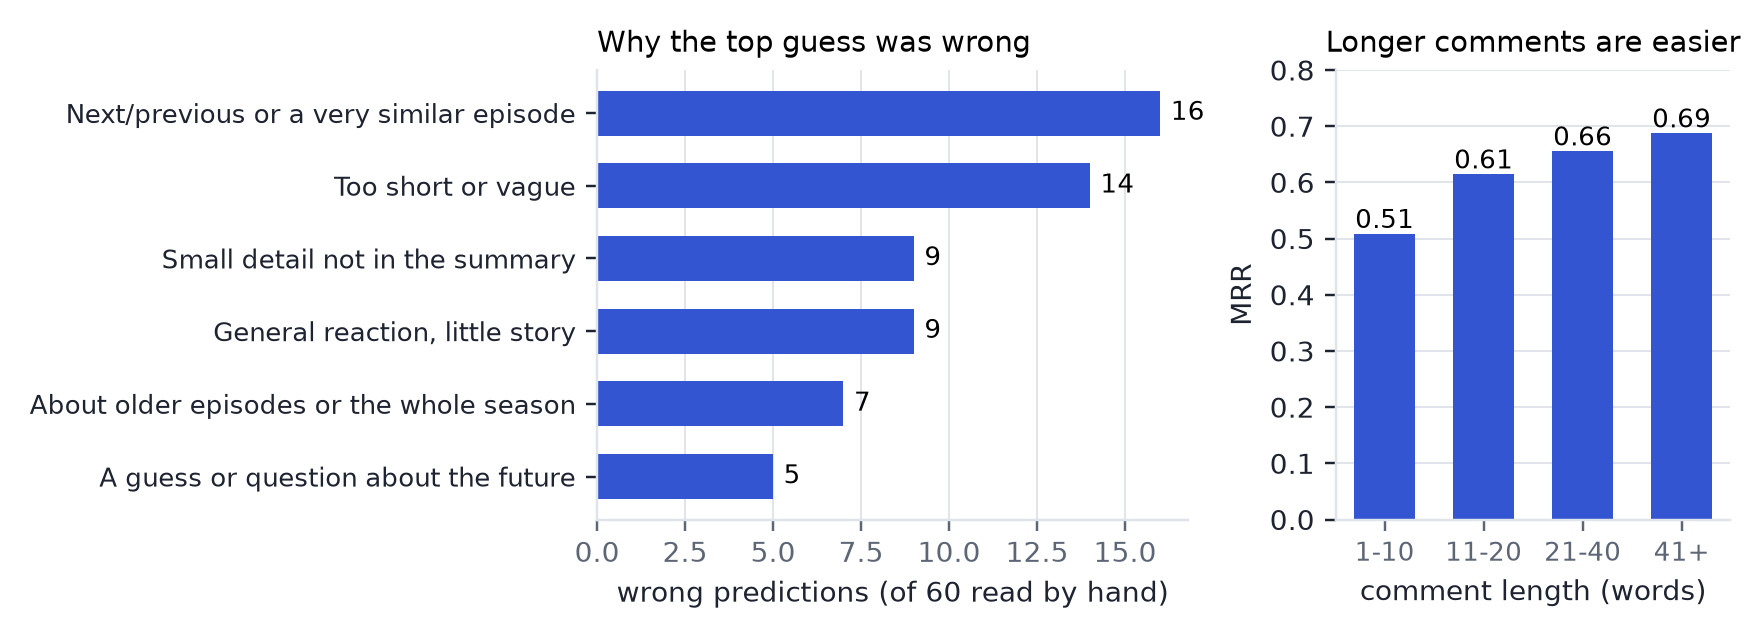

In [ ]:
# @title 17.1c Figure used in the report
from IPython.display import Image as _Img
display(_Img(f"{PROJECT}/results/figures/fig3_errors.png", width=900))

### 17.2 F2: does the matcher help the plot classifier?

**Idea.** A comment about the plot ("Levi killed the Beast Titan") is very close to *one* piece of an episode summary.
A general comment ("this episode was fun") is not close to any piece. So the best similarity between the comment and the show's summary pieces
could be a second clue next to the classifier's P(plot).

**How.** Four numbers per comment: logit of P(plot), best cosine (v6 bi-encoder), best BM25, length. A small logistic regression combines them.
It is fitted only on the dev part of the non-test shows (comments the classifier did not train on). The v6 bi-encoder never saw these shows.

In [ ]:
show("relevance_match.py")
if RUN_F:
    !python relevance_match.py
from sklearn.metrics import roc_auc_score
_old = pd.read_parquet(f"{PROJECT}/results/relevance_pred__relevance_ft_base.parquet")
_new = pd.read_parquet(f"{PROJECT}/results/relevance_pred__relevance_match.parquet")
_ft = pd.read_csv(f"{PROJECT}/results/relevance_features.csv"); _ft = _ft[_ft.show.isin(_old.show.unique())]
print(f"test-show AUC: classifier alone {roc_auc_score(_old.label, _old.p_rel):.3f} | best cosine alone {roc_auc_score(_ft.label, _ft.max_cos):.3f} | combined {roc_auc_score(_new.label, _new.p_rel):.3f}")

**`src/relevance_match.py`**

"""F2: better "is this comment about the plot?" by also asking the episode matcher.

Idea: a plot comment ("Levi killed the Beast Titan") is very close to ONE part of an episode summary.
A general comment ("this episode was fun") is not really close to any part.
So the matcher's best similarity is a second clue next to the classifier's P(plot).

Features per comment (all from models we already have, nothing new is trained except a tiny logistic regression):
  1. logit of P(plot) from the fine-tuned classifier (relevance_ft_base)
  2. best cosine similarity between the comment and any summary chunk of its show (v6_bi)
  3. best BM25 score over the summary chunks (word overlap)
  4. number of words (log)
The logistic regression is fitted ONLY on the dev part of the 4 non-test shows (the same 15% held-out split as
relevance.py), so the classifier's training comments are not reused. Test shows are scored once.
v6_bi never saw these 4 shows in training (val shows were left out), so feature 2 is fair.

Writes results/relevance_pred__relevance_match.parquet (same rows/order as the other relevance files).
"""
import numpy as np
import pandas as pd
import torch
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from common import RESULTS, ROOT, chunk_text, load_summaries, tokenize
from relevance import TEST_SHOWS, load_relevance, predict_relevance

f = load_relevance()
summ = load_summaries()

# 1. classifier
f["p_rel"] = predict_relevance(str(ROOT / "models/relevance_ft_base"), f.comment.tolist())

# 2. + 3. matcher similarity
bi = SentenceTransformer(str(ROOT / "models/v6_bi"), device="cuda", model_kwargs={"dtype": torch.float16})
bi.max_seq_length = 384
q = bi.encode(["search_query: " + c for c in f.comment], batch_size=64, normalize_embeddings=True)
f["max_cos"], f["max_bm25"] = 0.0, 0.0
for show, idx in f.groupby("show").groups.items():
    chunks = [c for t in summ[show][1] for c in chunk_text(t)]
    e = bi.encode(["search_document: " + c for c in chunks], batch_size=32, normalize_embeddings=True)
    f.loc[idx, "max_cos"] = (q[idx] @ e.T).max(1)
    bm = BM25Okapi([tokenize(c) for c in chunks])
    f.loc[idx, "max_bm25"] = [bm.get_scores(tokenize(c)).max() for c in f.loc[idx, "comment"]]
f["log_words"] = np.log1p(f.comment.str.split().str.len())

# same split as relevance.py: shuffle non-test shows with seed 0, first 15% = dev
pool = f[~f.show.isin(TEST_SHOWS)].sample(frac=1, random_state=0)
dev = pool.iloc[:int(0.15 * len(pool))]
te = f[f.show.isin(TEST_SHOWS)].reset_index(drop=True)

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))
feats = lambda d: np.c_[logit(d.p_rel), d.max_cos, np.log1p(d.max_bm25), d.log_words]
lr = LogisticRegression(C=1.0, max_iter=1000).fit(feats(dev), dev.label)
te["p_new"] = lr.predict_proba(feats(te))[:, 1]

print(f"dev comments used to fit: {len(dev)}, test comments: {len(te)}")
print(f"test AUC  classifier alone {roc_auc_score(te.label, te.p_rel):.3f}")
print(f"test AUC  best cosine alone {roc_auc_score(te.label, te.max_cos):.3f}")
print(f"test AUC  classifier + matcher {roc_auc_score(te.label, te.p_new):.3f}")
print("weights (logit p, max cos, log bm25, log words):", lr.coef_.round(2), lr.intercept_.round(2))
for show, g in te.groupby("show"):
    print(f"  {show:28s} {roc_auc_score(g.label, g.p_rel):.3f} -> {roc_auc_score(g.label, g.p_new):.3f}")

out = te[["comment", "show", "episode", "label"]].copy()
out["p_rel"] = te.p_new
out.to_parquet(RESULTS / "relevance_pred__relevance_match.parquet")
f.drop(columns=["comment"]).to_csv(RESULTS / "relevance_features.csv", index=False)

test-show AUC: classifier alone 0.884 | best cosine alone 0.798 | combined 0.884


**Result: no gain.** The best similarity alone is a decent clue (AUC 0.80), but it adds nothing to the fine-tuned classifier (0.884 → 0.884):
the classifier already knows what the similarity knows. The plot classifier stays the filter's weakest part; more labels or an LLM are still the open options.

### 17.3 The demo

`demo.py` runs the **whole filter** on one comment, with the same models and settings as the results:
P(plot) from `relevance_ft_base`, P(episode) from v6 (stage 1 → top 15 episodes → reranker on 4 pieces each, softmax with the val temperature T = 1.2512),
then P(spoiler) = P(plot) × P(episode after yours), hide if > 0.5.

Try your own: `!python demo.py attack_on_titan 70 "your comment"` (`!python demo.py --shows` lists the episode numbers).

In [ ]:
show("demo.py")
if RUN_DEMO:
    !python demo.py --examples

**`src/demo.py`**

"""Demo: the full progress-aware spoiler filter on one comment.

You give: a show, the last episode you watched, a comment.
It answers: is the comment about the plot? which episode is it about? should it be hidden from you?

Steps (the same models and settings as the results in the report):
  1. P(plot)      fine-tuned classifier (models/relevance_ft_base)
  2. episodes     v6 matcher: bi-encoder + BM25 keep the top 15 episodes, the reranker reads the 4 best
                  summary chunks of each; final = z(rerank) + 1.0 * z(stage 1); softmax with temperature T
                  (T = 1.2512, fitted on val in filter_eval.py) turns scores into probabilities
  3. P(spoiler)   = P(plot) x P(the comment is about an episode AFTER the one you watched)
                  hide the comment if P(spoiler) > 0.5

Usage
  python demo.py attack_on_titan 80 "Zeke got shot by Magath and fell off the wall"
  python demo.py --examples          # a few fixed examples
  python demo.py --shows             # list shows and their episode numbers
Runs on the laptop GPU (or CPU, slower). Needs models/v6_bi, models/v6_rr48_s2, models/relevance_ft_base.
"""
import sys

import numpy as np
import torch
from rank_bm25 import BM25Okapi
from scipy.special import softmax
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from common import ROOT, chunk_text, load_summaries, tokenize
from fuse import z

K, M, A, W_BM25, T, MAX_LEN = 15, 4, 1.0, 0.3, 1.2512, 384
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32


class SpoilerFilter:
    def __init__(self):
        self.summ = load_summaries()
        self.bi = SentenceTransformer(str(ROOT / "models/v6_bi"), device=DEV, model_kwargs={"dtype": DT})
        self.bi.max_seq_length = MAX_LEN
        self.rr_tok = AutoTokenizer.from_pretrained(ROOT / "models/v6_rr48_s2")
        self.rr = AutoModelForSequenceClassification.from_pretrained(ROOT / "models/v6_rr48_s2", dtype=DT).to(DEV).eval()
        self.rel_tok = AutoTokenizer.from_pretrained(ROOT / "models/relevance_ft_base")
        self.rel = AutoModelForSequenceClassification.from_pretrained(ROOT / "models/relevance_ft_base", dtype=DT).to(DEV).eval()
        self.index = {}

    def show_index(self, show):
        """Chunks, chunk vectors and BM25 index of one show (made once, then cached)."""
        if show not in self.index:
            docs, owner = [], []
            for i, t in enumerate(self.summ[show][1]):
                for c in chunk_text(t):
                    docs.append(c)
                    owner.append(i)
            owner = np.array(owner)
            e = self.bi.encode(["search_document: " + d for d in docs], batch_size=32, normalize_embeddings=True)
            self.index[show] = (docs, owner, e, BM25Okapi([tokenize(d) for d in docs]))
        return self.index[show]

    @torch.no_grad()
    def p_plot(self, comments):
        b = self.rel_tok(comments, truncation=True, max_length=128, padding=True, return_tensors="pt").to(DEV)
        return torch.softmax(self.rel(**b).logits.float(), -1)[:, 1].cpu().numpy()

    @torch.no_grad()
    def episode_probs(self, show, comment):
        docs, owner, e, bm = self.show_index(show)
        n = len(self.summ[show][0])
        sims = e @ self.bi.encode("search_query: " + comment, normalize_embeddings=True)
        dense = np.array([sims[owner == i].max() for i in range(n)])
        lex = np.full(n, -1e9)
        np.maximum.at(lex, owner, bm.get_scores(tokenize(comment)))
        first = z(dense) + W_BM25 * z(lex)                     # stage 1
        top = np.argsort(-first)[:K]
        pairs, who = [], []
        for j in top:                                          # stage 2: M best chunks of each top episode
            idx = np.where(owner == j)[0]
            for c in idx[np.argsort(-sims[idx])][:M]:
                pairs.append((comment, docs[c]))
            


attack_on_titan, you watched up to episode 70
  comment: "The emotional whiplash Yelena experienced from seeing her God in Zeke light up those Marley blimps to watching said God get sniped by Magath and tumble off the Wall"
  about the plot?          100%
  most likely episodes:    ep 85 (27%), ep 77 (23%), ep 68 (22%)
  about a later episode?   74%
  P(spoiler for you)       74%  ->  HIDE



attack_on_titan, you watched up to episode 85
  comment: "The emotional whiplash Yelena experienced from seeing her God in Zeke light up those Marley blimps to watching said God get sniped by Magath and tumble off the Wall"
  about the plot?          100%
  most likely episodes:    ep 85 (27%), ep 77 (23%), ep 68 (22%)
  about a later episode?   0%
  P(spoiler for you)       0%  ->  show



attack_on_titan, you watched up to episode 70
  comment: "This episode was so good, the animation was amazing"
  about the plot?          0%
  most likely episodes:    ep 52 (37%), ep 53 (20%), ep 60 (11%)
  about a later episode?   7%
  P(spoiler for you)       0%  ->  show



legend_of_korra, you watched up to episode 10
  comment: "So Korra lost her memory, right?"
  about the plot?          71%
  most likely episodes:    ep 41 (23%), ep 8 (23%), ep 4 (14%)
  about a later episode?   54%
  P(spoiler for you)       38%  ->  show


`make_demo_data.py` runs the same filter on 200 real test comments (50 per show: 36 about the story, 14 not) and saves the outputs to
`results/demo_comments.json`. `report/demo.html` reads them: pick a show, move "I have watched up to episode …", and see what is hidden.
It needs no GPU and works offline.

In [ ]:
show("make_demo_data.py")

**`src/make_demo_data.py`**

"""Make the data for report/demo.html: real test comments with the filter's real outputs.

For each test show we take a fixed random sample of short hand-labelled comments (plot and non-plot),
run the full filter (demo.py) on them and save P(plot) and P(episode) for every episode.
The page then decides hide/show for any viewer position without running a model.
"""
import json

import pandas as pd

from common import RESULTS, ROOT
from demo import SpoilerFilter
from relevance import TEST_SHOWS, load_relevance

f = load_relevance()
te = f[f.show.isin(TEST_SHOWS)]
te = te[te.comment.str.split().str.len().between(6, 35)]
flt = SpoilerFilter()
out = {}
for show in sorted(TEST_SHOWS):
    g = te[te.show == show]
    pick = pd.concat([g[g.label == 1].sample(36, random_state=1), g[g.label == 0].sample(14, random_state=1)])
    pick = pick.sample(frac=1, random_state=2)
    eps = flt.summ[show][0]
    pp = flt.p_plot(pick.comment.tolist())
    rows = []
    for (c, ep, lab), p_plot in zip(pick[["comment", "episode", "label"]].itertuples(index=False), pp):
        p = flt.episode_probs(show, c)
        rows.append({"c": c, "ep": int(ep), "plot": int(lab), "pp": round(float(p_plot), 3),
                     "pe": [round(float(x), 4) for x in p]})
    out[show] = {"episodes": [int(e) for e in eps], "comments": rows}
    print(show, len(rows))
json.dump(out, open(RESULTS / "demo_comments.json", "w"))

### 17.4 What we found

- **Right episode first 51%, top 3 72%, top 5 80%.** Shows with more episodes are harder: Arcane 0.71 (9 episodes), Korra 0.67 (27), Kaguya-sama 0.61 (19), Attack on Titan 0.59 (62).
- **Short comments are hard:** MRR 0.51 for 1–10 words, 0.69 for 41+ words.
- **When the top guess is wrong**, it is 1 episode away 20% of the time and points to an *earlier* episode 63% of the time.
- **Kinds of errors (60 read by hand):** next/previous or similar episode 27%, too short or vague 23%, detail not in the summary 15%, general reaction 15%, about older episodes or the whole season 12%, guess about the future 8%. Most of these are hard for a person too.
- **F2:** matcher features do not help the plot classifier (0.884 → 0.884).
- **Deliverables made from this:** `report/final_report.pdf`, `report/slides.pdf`, `report/demo.html` (figures from `src/figures.py`).

## 18. All versions in one place

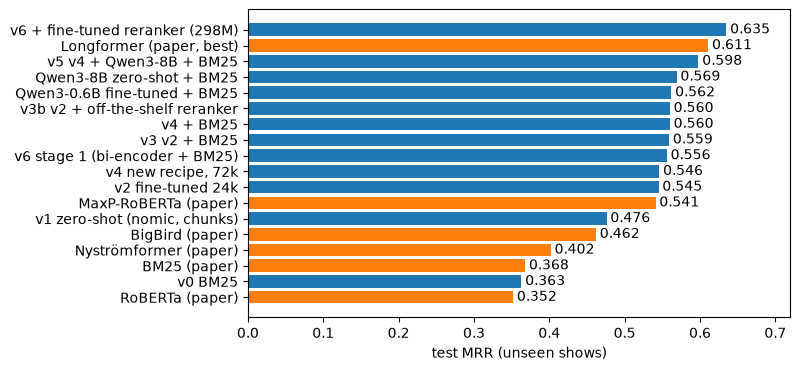

,model,MRR,top1,top3
0,bm25,0.356,0.211,0.399
1,bm25_chunks,0.363,0.212,0.413
2,bge_base_chunks,0.369,0.215,0.425
3,qwen3_emb_0.6b_full,0.403,0.260,0.450
4,bge_m3_full,0.415,0.259,0.475
5,gte_modernbert_full,0.416,0.262,0.475
6,minilm_chunks,0.423,0.266,0.487
7,nomic_modernbert_full,0.425,0.271,0.486
8,qwen3_emb_4b_full,0.438,0.288,0.494
9,gte_modernbert_chunks,0.448,0.289,0.529


In [ ]:
# @title 18.1 Test MRR: our versions vs the paper
VERSION = {"bm25_chunks": "v0 BM25", "nomic_modernbert_chunks": "v1 zero-shot (nomic, chunks)",
           "ft_nomic_24k": "v2 fine-tuned 24k", "ft_nomic_24k+bm25_w0.3": "v3 v2 + BM25",
           "ft_nomic_24k+gte_rr_chunks_k10": "v3b v2 + off-the-shelf reranker",
           "v4_72k": "v4 new recipe, 72k", "v4_72k+bm25_w0.3": "v4 + BM25", "qwen3_ft_24k+bm25_w0.3": "Qwen3-0.6B fine-tuned + BM25",
           "qwen3_emb_8b_chunks+bm25_w0.2": "Qwen3-8B zero-shot + BM25", "v4_72k+qwen3_emb_8b+bm25": "v5 v4 + Qwen3-8B + BM25",
           "v6_first": "v6 stage 1 (bi-encoder + BM25)", "v6_rr48_s2": "v6 + fine-tuned reranker (298M)"}
r = results("test"); ours = r[r.model.isin(VERSION)].assign(name=lambda d: d.model.map(VERSION), who="ours")
paper = pd.DataFrame({"name": ["RoBERTa (paper)", "BM25 (paper)", "Nyströmformer (paper)", "BigBird (paper)", "MaxP-RoBERTa (paper)", "Longformer (paper, best)"],
                      "MRR": [.352, .368, .402, .462, .541, .611], "who": "paper"})
allv = pd.concat([ours[["name", "MRR", "who"]], paper]).sort_values("MRR")
plt.figure(figsize=(7, 4)); plt.barh(allv.name, allv.MRR, color=["tab:blue" if w == "ours" else "tab:orange" for w in allv.who])
for i, v in enumerate(allv.MRR): plt.text(v + .005, i, f"{v:.3f}", va="center")
plt.xlim(0, .72); plt.xlabel("test MRR (unseen shows)"); plt.show()
display(results("test"))

In [ ]:
# @title 18.2 Per-show test MRR (where does each version struggle?)
full = pd.read_csv(f"{PROJECT}/results/matching_results.csv")
full = full[(full.split.fillna("test") == "test") & full.model.isin(VERSION)]
full.set_index(full.model.map(VERSION))[[c for c in full.columns if c.startswith("MRR_") and full[c].notna().any()]].round(3)

,MRR_arcane,MRR_attack_on_titan,MRR_kaguya_sama_love_is_war,MRR_legend_of_korra
model,,,,
v3b v2 + off-the-shelf reranker,0.637,0.509,0.556,0.592
v0 BM25,0.453,0.282,0.411,0.411
"v1 zero-shot (nomic, chunks)",0.563,0.416,0.489,0.511
v2 fine-tuned 24k,0.623,0.503,0.535,0.572
"v4 new recipe, 72k",0.639,0.504,0.488,0.578
v3 v2 + BM25,0.625,0.512,0.561,0.588
v4 + BM25,0.643,0.507,0.536,0.597
Qwen3-0.6B fine-tuned + BM25,0.633,0.509,0.560,0.597
Qwen3-8B zero-shot + BM25,0.680,0.487,0.630,0.612


## 19. Next experiments (we decide together)

Each new version gets its own section above section 18, a row in the versions table, and a note here. **Rule:** choose settings on **val** (the val shows are now left out of all training), look at **test** once, and use 3 seeds before claiming a gain smaller than ~0.01.

Target **0.611** (paper) is beaten: v6 = **0.637 ± 0.002** (3 seeds, 298M).

| # | Idea | Why it should help | Time | Status |
|---|---|---|---|---|
| A1–A5, B1–B3, F1 | (see sections 13–15) | | | **done** |
| G1 | show-held-out val split | honest model selection | | **done (16)**: val ≈ test now |
| C1 | fine-tune a cross-encoder reranker | the paper's best is a cross-encoder | | **done (16)**: 0.556 → 0.637 |
| S1 | 3 seeds | | | **done for the reranker (16)**: ± 0.002 |
| F2 | plot classifier + matcher similarity as extra features | plot comments are close to one summary piece | | **tried (17.2): no gain (AUC 0.884 → 0.884)**; LLM or more labels still open |
| N1 | **new shows** (aired after the dataset): Reddit episode threads + Fandom summaries | does v6 work on shows nobody has seen? | ~1 day (data) | proposed |
| N2 | **movies** (IMDB Spoiler Dataset: reviews + plot synopsis, spoiler yes/no) | matching score vs plot synopsis as a zero-shot spoiler detector | ~2 h | proposed |
| N3 | **book series** (Goodreads spoiler reviews; series = show, book = episode, Wikipedia plot = summary) | progress-aware filtering for books | ~1 day | proposed |
| N4 | games | no public spoiler dataset found; would need our own labels | days | future work |
| E1 | speed: smaller K/M, or distil the reranker into a smaller one | 0.620 at K=10, M=2 already, 2× faster | ~1 h | proposed |
| A4 | re-mine hard negatives with the fine-tuned model | positives were picked by the untrained model | ~30 min | proposed |
| D1 | "episode cards": an LLM writes key events per episode, once | bridges chatty comments vs formal summaries | ~1 h | proposed |